Enzo Ambrosio da Costa

Isaac Pereira Cerceau Netto

Vitor Riki Araujo Furuta

# <font color = Blue> **Trabalho Final — Problema 04 - Eletricidade Victoria**

**`Objetivo do trabalho`**:  modelar um *problema real* e fazer predição utilizando os modelos de séries temporais estudados na disciplina.

**`Problema Real`**: Modelagem e predição de demanda média diária de eletricidade no estado de Victoria, Austrália - **de 01/01/2012 a 31/12/2014**.

**`Tarefa`**: encontrar o melhor modelo e fazer a predição (**forecast**) de demanda média diária de eletricidade no estado de Victoria, Austrália para um horizonte **`h`**, que será definido adiante.


**`Abordagem`**: todos os modelos usam a **série de demanda original** (sem tratamento) e a **sazonalidade de 7 dias**. O Prophet recebe também o **período de festas** como data especial e a **temperatura do ano anterior suavizada** como regressor (informação já conhecida no momento da previsão).

## <font color = Blue> **Configuração Inicial e Carregamento da Série**
Vamos instalar/importar as bibliotecas necessárias e carregar a série temporal.

- **Bibliotecas básicas**

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # esconde os logs do tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Esconde os logs do prophet (cmdstanpy)
import logging
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet.plot').disabled = True
logging.getLogger('prophet.models').setLevel(logging.ERROR)
from matplotlib.lines import Line2D  # legenda das estacoes do ano
from prophet.utilities import regressor_coefficients

# Imports basicos
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA
from sklearn.tree import DecisionTreeRegressor
from prophet import Prophet
import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import root_mean_squared_error

# Esconde os avisos do statsmodels
import warnings
warnings.filterwarnings('ignore')

- **Cores padrão dos gráficos** (cores vivas, para ficarem fáceis de ver no fundo branco)

In [2]:
COR_SERIE = '#1565C0'     # azul
COR_DESTAQUE = '#FF6D00'  # laranja
COR_TESTE = '#00A651'     # verde
COR_SARIMA = '#E91E63'    # rosa
COR_PROPHET = '#7B1FA2'   # roxo
COR_OUTROS = '#00838F'    # azul-petróleo
COR_ALERTA = '#D50000'    # vermelho
COR_TEMP = '#BF360C'      # laranja escuro

- **Carregamento da Série `Eletricidade Victoria`**

Fonte e preparação: AEMO, disponibilizada em tsibbledata::vic_elec. Média por data local das leituras de 30 minutos; não representa energia diária em MWh. Fonte: https://fpp.robjhyndman.com/hyndsight/electrictsibbles/index.html ; CSV de origem: https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/tsibbledata/vic_elec.csv

O CSV será carregado diretamente do repositório GitHub `MiroPlacido/Datasets`: `AST_2026_Problema_04_Eletricidade_Victoria.csv`.

In [3]:
url = 'https://raw.githubusercontent.com/MiroPlacido/Datasets/refs/heads/main/AST_2026_Problema_04_Eletricidade_Victoria.csv'
df = pd.read_csv(url)

df.head()

,Data,Demanda_Media_MW
0,2012-01-01,4634.123156
1,2012-01-02,5374.265075
2,2012-01-03,5564.554279
3,2012-01-04,4640.464311
4,2012-01-05,4387.192503


In [4]:
# Identificando a data e setando como índice
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data")

# Frequência para diária
df.index.freq = 'D'

df.head()

,Demanda_Media_MW
Data,
2012-01-01,4634.123156
2012-01-02,5374.265075
2012-01-03,5564.554279
2012-01-04,4640.464311
2012-01-05,4387.192503


In [5]:
# Base original vic_elec (leituras de 30 em 30 minutos), usada só na análise exploratória
url_original = 'https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/tsibbledata/vic_elec.csv'
df_original = pd.read_csv(url_original)
df_original["Date"] = pd.to_datetime(df_original["Date"])

# Temperatura média e feriado de cada dia
df_features = df_original.groupby("Date").agg(Temperatura_Media=("Temperature", "mean"), Feriado=("Holiday", "max"))

# Junta ao df da demanda
df = df.join(df_features, how="left")
df["Feriado"] = df["Feriado"].astype(bool)
df.index.freq = "D"

- **Plot da série ORIGINAL**

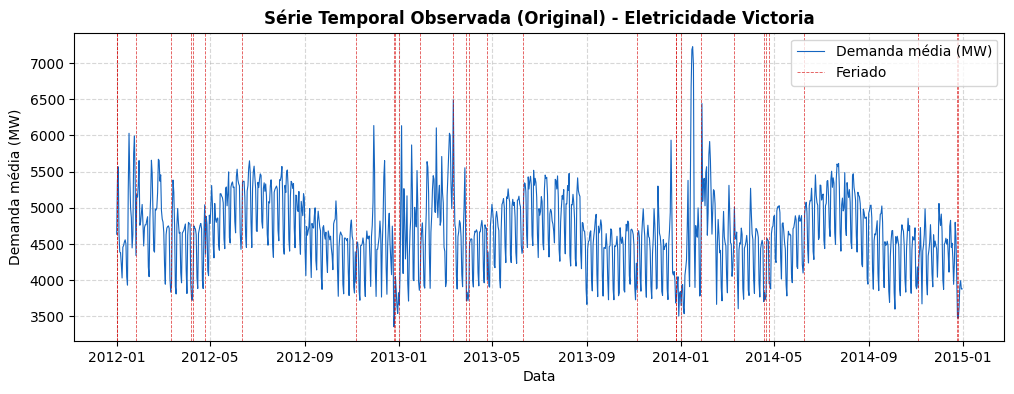

In [6]:
# Visualização da série com marcação de feriados
plt.figure(figsize=(12, 4))
plt.plot(df.Demanda_Media_MW, label='Demanda média (MW)', color=COR_SERIE, linewidth=0.8)

feriados = df[df['Feriado'] == True].index
for i, data_feriado in enumerate(feriados):
    plt.axvline(x=data_feriado, color=COR_ALERTA, linestyle='--', linewidth=0.6, alpha=0.7, label='Feriado' if i == 0 else "")

plt.title('Série Temporal Observada (Original) - Eletricidade Victoria', fontweight="bold")
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

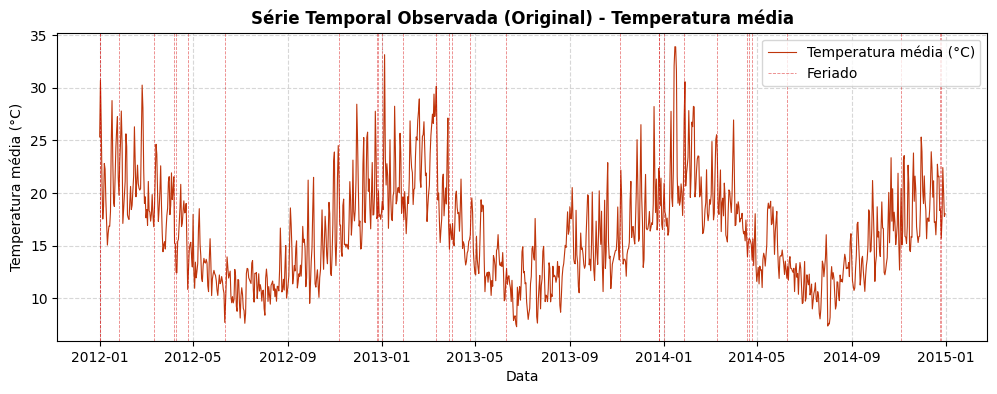

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(df.Temperatura_Media, label='Temperatura média (°C)', color=COR_TEMP, linewidth=0.8)

feriados = df[df['Feriado'] == True].index
for i, data_feriado in enumerate(feriados):
    plt.axvline(x=data_feriado, color=COR_ALERTA, linestyle='--', linewidth=0.6, alpha=0.5, label='Feriado' if i == 0 else "")

plt.title('Série Temporal Observada (Original) - Temperatura média', fontweight="bold")
plt.xlabel('Data')
plt.ylabel('Temperatura média (°C)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

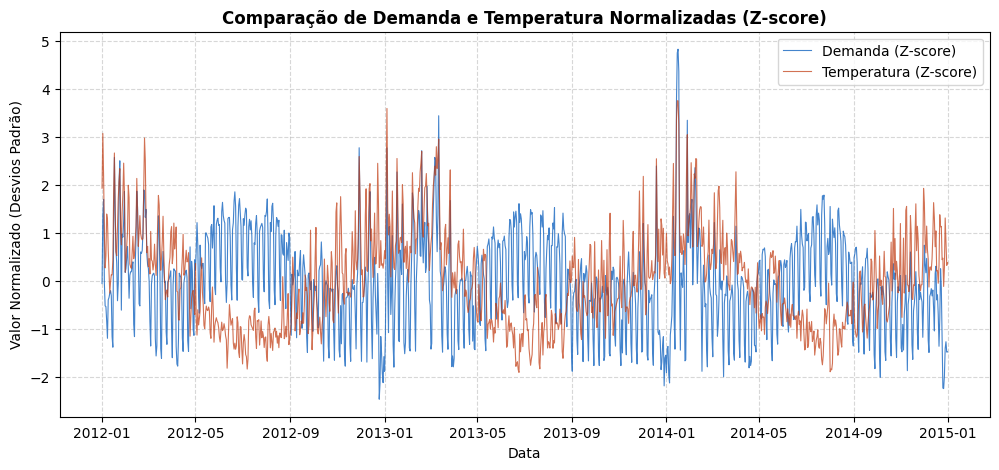

In [8]:
# Normalização por Z-score
demanda_zscore = (df['Demanda_Media_MW'] - df['Demanda_Media_MW'].mean()) / df['Demanda_Media_MW'].std()
temperatura_zscore = (df['Temperatura_Media'] - df['Temperatura_Media'].mean()) / df['Temperatura_Media'].std()

plt.figure(figsize=(12, 5))
plt.plot(demanda_zscore, label='Demanda (Z-score)', color=COR_SERIE, linewidth=0.8, alpha=0.8)
plt.plot(temperatura_zscore, label='Temperatura (Z-score)', color=COR_TEMP, linewidth=0.8, alpha=0.7)
plt.title('Comparação de Demanda e Temperatura Normalizadas (Z-score)', fontweight="bold")
plt.xlabel('Data')
plt.ylabel('Valor Normalizado (Desvios Padrão)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

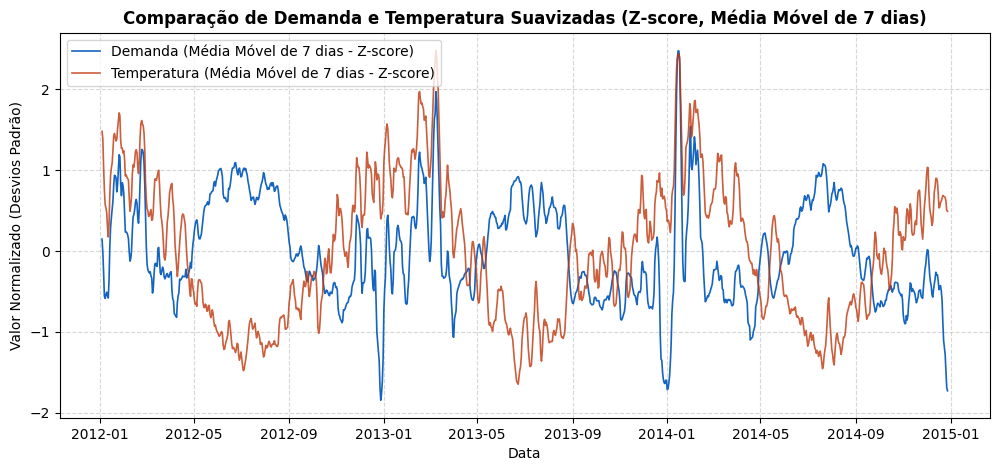

In [9]:
# Média móvel de 7 dias para tirar o padrão semanal
demanda_zscore_suave = demanda_zscore.rolling(window=7, center=True).mean()
temperatura_zscore_suave = temperatura_zscore.rolling(window=7, center=True).mean()

plt.figure(figsize=(12, 5))
plt.plot(demanda_zscore_suave, label='Demanda (Média Móvel de 7 dias - Z-score)', color=COR_SERIE, linewidth=1.2)
plt.plot(temperatura_zscore_suave, label='Temperatura (Média Móvel de 7 dias - Z-score)', color=COR_TEMP, linewidth=1.2, alpha=0.8)
plt.title('Comparação de Demanda e Temperatura Suavizadas (Z-score, Média Móvel de 7 dias)', fontweight="bold")
plt.xlabel('Data')
plt.ylabel('Valor Normalizado (Desvios Padrão)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

- **Temperatura em valor absoluto**: como a demanda sobe tanto no frio quanto no calor, comparamos a demanda com a *distância* da temperatura em relação à média.

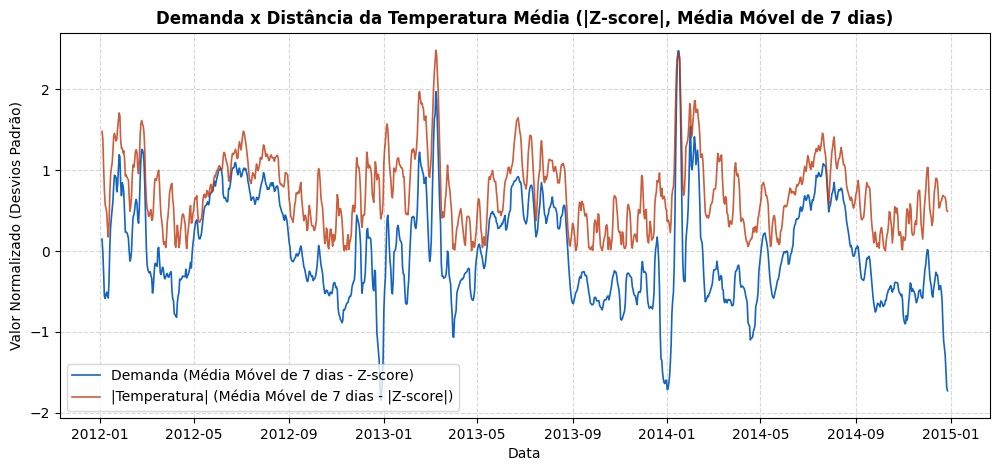

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(demanda_zscore_suave, label='Demanda (Média Móvel de 7 dias - Z-score)', color=COR_SERIE, linewidth=1.2)
plt.plot(np.abs(temperatura_zscore_suave), label='|Temperatura| (Média Móvel de 7 dias - |Z-score|)', color=COR_TEMP, linewidth=1.2, alpha=0.8)
plt.title('Demanda x Distância da Temperatura Média (|Z-score|, Média Móvel de 7 dias)', fontweight="bold")
plt.xlabel('Data')
plt.ylabel('Valor Normalizado (Desvios Padrão)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

- **Dispersão demanda x temperatura**: cada ponto é um dia do treino (2012-2013). Os dias úteis e os dias de folga (sábado, domingo ou feriado) aparecem em cores diferentes.

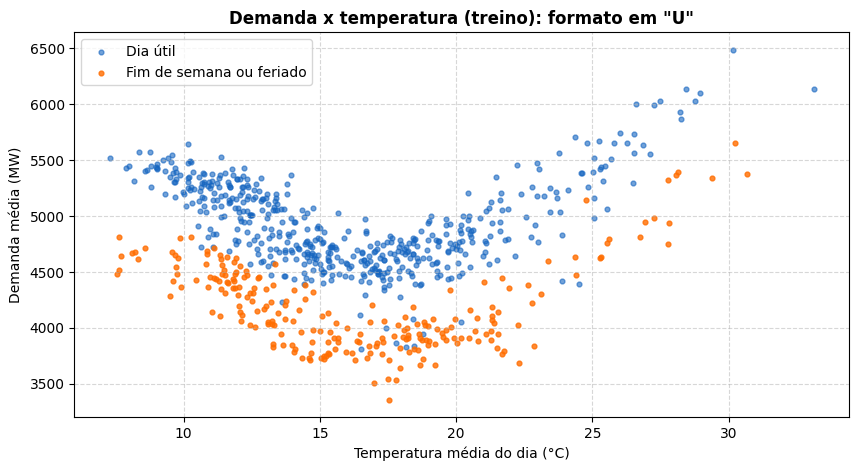

In [11]:
# Só o treino 2012-2013
explor = df.loc['2012':'2013'].copy()
folga = (explor.index.dayofweek >= 5) | explor['Feriado']  # sábado, domingo ou feriado

plt.figure(figsize=(10, 5))
plt.scatter(explor.Temperatura_Media[~folga], explor.Demanda_Media_MW[~folga], s=12, color=COR_SERIE, alpha=0.6, label='Dia útil')
plt.scatter(explor.Temperatura_Media[folga], explor.Demanda_Media_MW[folga], s=12, color=COR_DESTAQUE, alpha=0.8, label='Fim de semana ou feriado')
plt.title('Demanda x temperatura (treino): formato em "U"', fontweight='bold')
plt.xlabel('Temperatura média do dia (°C)')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

- **Correlação de Pearson**: com a temperatura e com a *distância* da temperatura em relação à média (|z-score|)

In [12]:
z_temp = (explor.Temperatura_Media - explor.Temperatura_Media.mean()) / explor.Temperatura_Media.std()

r_temp = explor.Demanda_Media_MW.corr(explor.Temperatura_Media)
r_abs = explor.Demanda_Media_MW.corr(z_temp.abs())
r_abs_util = explor.Demanda_Media_MW[~folga].corr(z_temp.abs()[~folga])

print("Demanda x temperatura:", round(r_temp, 2))
print("Demanda x |z-score| da temperatura:", round(r_abs, 2))
print("Demanda x |z-score| da temperatura (só dias úteis):", round(r_abs_util, 2))

# Faixa de 2 °C com a menor demanda média (dias úteis)
faixa = (explor.Temperatura_Media[~folga] // 2) * 2
media_faixa = explor.Demanda_Media_MW[~folga].groupby(faixa).mean()
print("Menor demanda média (dias úteis) na faixa de", int(media_faixa.idxmin()), "a", int(media_faixa.idxmin()) + 2, "°C")

Demanda x temperatura: 0.0
Demanda x |z-score| da temperatura: 0.57
Demanda x |z-score| da temperatura (só dias úteis): 0.78
Menor demanda média (dias úteis) na faixa de 16 a 18 °C


- **A temperatura do mesmo dia no ano anterior ajuda?** Se ela explicasse a demanda, seria uma informação já conhecida na hora de prever. Comparamos a demanda de 2013 com o |z-score| da temperatura do **mesmo dia** e da **mesma data em 2012**.

In [13]:
datas_2013 = explor.loc['2013'].index
abs_z = z_temp.abs()
demanda_2013 = explor.Demanda_Media_MW.loc['2013']

abs_z_ano_anterior = pd.Series(abs_z.reindex(datas_2013 - pd.DateOffset(years=1)).values, index=datas_2013)

r_mesmo_dia = demanda_2013.corr(abs_z.loc['2013'])
r_ano_anterior = demanda_2013.corr(abs_z_ano_anterior)

print("Demanda 2013 x |z| da temperatura do mesmo dia:", round(r_mesmo_dia, 2))
print("Demanda 2013 x |z| da temperatura da mesma data em 2012:", round(r_ano_anterior, 2))

Demanda 2013 x |z| da temperatura do mesmo dia: 0.62
Demanda 2013 x |z| da temperatura da mesma data em 2012: 0.14


### <font color = Blue> **Relação entre demanda, temperatura e feriados**

- **Formato em "U":** nos dias úteis, a menor demanda média fica na faixa de **16 a 18 °C**, quando quase não se usa aquecimento nem ar-condicionado. No frio a demanda sobe pelo **aquecimento** e no calor pelo **ar-condicionado**.
- **Por que a correlação "comum" engana:** a correlação de Pearson entre demanda e temperatura é **0,00**. Ela só mede relação **linear**, e o efeito do frio e o do calor se cancelam. Com a *distância* da temperatura em relação à média (|z-score|), a correlação sobe para **0,57**, e para **0,78** considerando só os dias úteis.
- **Dois picos por ano:** em Melbourne o inverno é longo e frio, então o pico de inverno é largo e alto. O calor do verão vem em ondas curtas, que geram picos isolados muito altos.
- **Dias de folga:** no gráfico de dispersão, sábados, domingos e feriados formam um "U" **mais baixo**. Para a mesma temperatura, a demanda cai porque comércio, escritórios e indústrias param. Um feriado em dia útil se comporta quase como um domingo.
- **A temperatura nos modelos:**
  - A temperatura do **próprio dia** não pode ser usada para prever: em 2015 ela ainda não seria conhecida.
  - A temperatura do **mesmo dia do ano anterior**, que já é conhecida, quase não explica a demanda: a correlação com a demanda de 2013 cai de **0,62** (mesmo dia) para **0,14** (mesma data de 2012). O tempo de um dia específico não se repete de um ano para o outro.
  - **Suavizada** por média móvel, porém, a temperatura do ano anterior mostra o **ciclo das estações**, que se repete. Por isso a única exceção é o **Prophet**, que recebe esse valor suavizado como regressor extra (Parte 4.5). Os outros modelos usam **só a série de demanda**.

## <font color = Blue> **Parte 1 - Divisão ($split$) da série temporal**

- **Defina e justifique o horizonte `h` de predição**.
- Um horizonte múltiplo do período sazonal `m` é conveniente;
- Reserve os **últimos `h` dias para teste**, utilizando os dados anteriores como treino e validação;

- **Horizonte: `h = 365` dias (o ano de 2014 inteiro)**
  - **Treino:** 2012 e 2013 (731 dias, ~66,7%).
  - **Teste:** 2014 (365 dias, ~33,3%).
  - Um ano de teste cobre todas as estações e é um horizonte natural para planejamento de energia. Também são 52 semanas completas (+1 dia), então o padrão semanal fica equilibrado.

In [14]:
h = 365

df_treino = df.loc['2012-01-01':'2013-12-31']
df_teste = df.loc['2014-01-01':'2014-12-31']

y_treino = df_treino.Demanda_Media_MW
y_teste = df_teste.Demanda_Media_MW

print("Treino:", len(y_treino), "dias -", round(len(y_treino) / len(df) * 100, 1), "%")
print("Teste:", len(y_teste), "dias -", round(len(y_teste) / len(df) * 100, 1), "%")
print("h =", h, "dias")

Treino: 731 dias - 66.7 %
Teste: 365 dias - 33.3 %
h = 365 dias


- **Plot o split da série, isto é, os conjuntos de treino e teste**

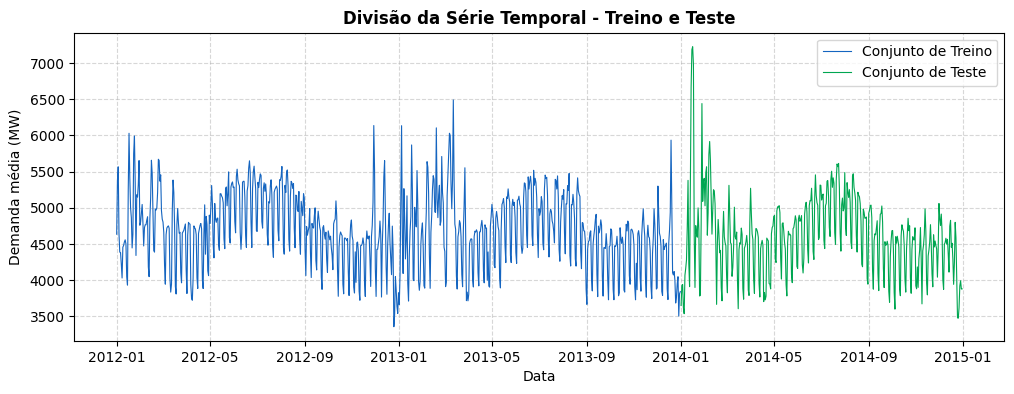

In [15]:
plt.figure(figsize=(12, 4))
plt.plot(df_treino.Demanda_Media_MW, label='Conjunto de Treino', color=COR_SERIE, linewidth=0.8)
plt.plot(df_teste.Demanda_Media_MW, label='Conjunto de Teste', color=COR_TESTE, linewidth=0.8)
plt.title('Divisão da Série Temporal - Treino e Teste', fontweight="bold")
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

- **Validação dentro do treino x teste**

O enunciado pede que a escolha do modelo seja feita **só dentro do treino**, com blocos de validação do mesmo tamanho de `h`. Como o treino tem 2 anos, a única janela possível é:

| Etapa | Treina com | Prevê | Para que serve |
|---|---|---|---|
| Validação (Parte 4) | 2012 | 2013 | escolher o modelo |
| Teste (Parte 5) | 2012 + 2013 | 2014 | avaliar o modelo escolhido |
| Previsão (Parte 6) | 2012 + 2013 + 2014 | 2015 | forecast final |

Ou seja, 2013 é usado como **validação** só na escolha. Depois o modelo é treinado com 2012 e 2013 inteiros para prever o **teste (2014)**.

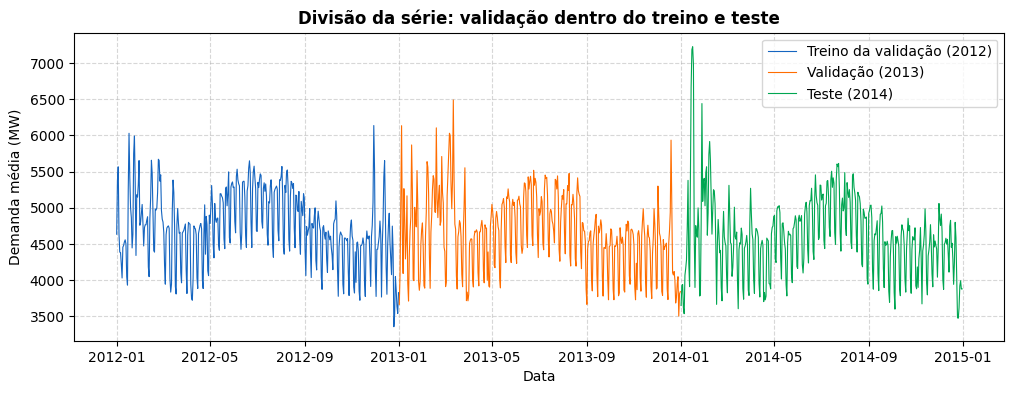

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(y_treino.loc['2012'], color=COR_SERIE, linewidth=0.8, label='Treino da validação (2012)')
plt.plot(y_treino.loc['2013'], color=COR_DESTAQUE, linewidth=0.8, label='Validação (2013)')
plt.plot(y_teste, color=COR_TESTE, linewidth=0.8, label='Teste (2014)')
plt.title('Divisão da série: validação dentro do treino e teste', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

## <font color = Blue> **Parte 2 - Tratamento da Série (Detecção e tratamento de anomalias)**

Verifique se o conjunto de treino precisa de algum tratamento. Deixe clara sua escolha, explicando o motivo.
- **Obs:** a escolha pode ser "nada a ajustar".

In [17]:
# Maiores e menores valores do treino
dias_pt = {0: 'segunda', 1: 'terça', 2: 'quarta', 3: 'quinta', 4: 'sexta', 5: 'sábado', 6: 'domingo'}

extremos = pd.concat([y_treino.nlargest(5), y_treino.nsmallest(5)]).to_frame('Demanda (MW)')
extremos['Dia'] = extremos.index.dayofweek.map(dias_pt)
extremos.round(0)

,Demanda (MW),Dia
Data,,
2013-03-12,6488.0,terça
2012-11-29,6135.0,quinta
2013-01-04,6133.0,sexta
2013-02-18,6103.0,segunda
2013-03-07,6028.0,quinta
2012-12-25,3356.0,terça
2013-12-29,3504.0,domingo
2012-12-26,3531.0,quarta
2012-12-30,3540.0,domingo


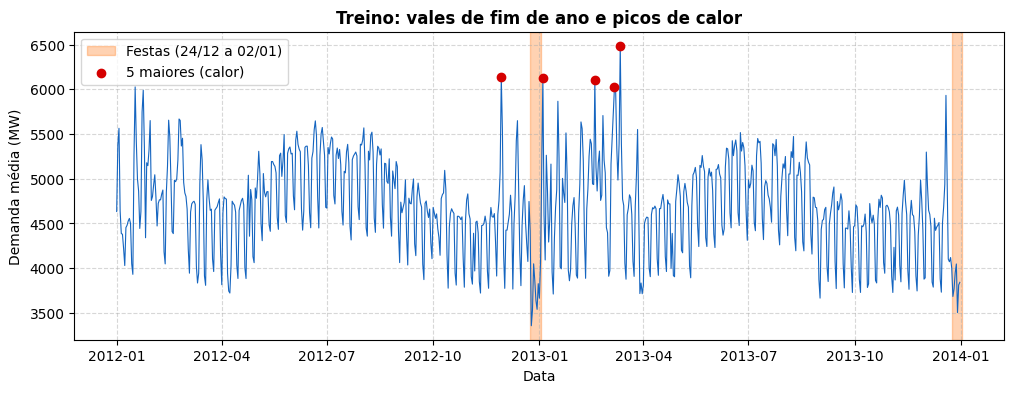

In [18]:
plt.figure(figsize=(12, 4))
plt.plot(y_treino, color=COR_SERIE, linewidth=0.8)
for ano in [2012, 2013]:
    plt.axvspan(pd.Timestamp(f'{ano}-12-24'), pd.Timestamp(f'{ano + 1}-01-02'), color=COR_DESTAQUE, alpha=0.3,
                label='Festas (24/12 a 02/01)' if ano == 2012 else '')
plt.scatter(y_treino.nlargest(5).index, y_treino.nlargest(5), color=COR_ALERTA, zorder=3, label='5 maiores (calor)')
plt.title('Treino: vales de fim de ano e picos de calor', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

- **Decisão: nada a ajustar**

  - **Picos** (ex.: 12/03/2013 com ~6.500 MW): dias de calor extremo. É um fenômeno real.
  - **Vales de fim de ano:** os menores valores do treino estão todos entre o Natal e o Ano Novo. Isso **não é um outlier aleatório**: acontece todo ano e tem causa conhecida (festas, férias coletivas, comércio e indústria parados).
  - Como os dois comportamentos se repetem e fazem parte da série real, **a série é mantida original** em todos os modelos. No Prophet, que permite informar datas especiais, o período de festas entra como **feriado** (Parte 4).

## <font color = Blue> **Parte 3 - Análise e Diagnóstico**
- Faça plot de um período curto do conjunto de treino (trecho ampliado) para identificar visualmente sazonalidade;
- Faça análises de autocorrelação, estacionariedade e sazonalidade utilizando o conjunto de treino.

- **Trecho ampliado (8 semanas)**

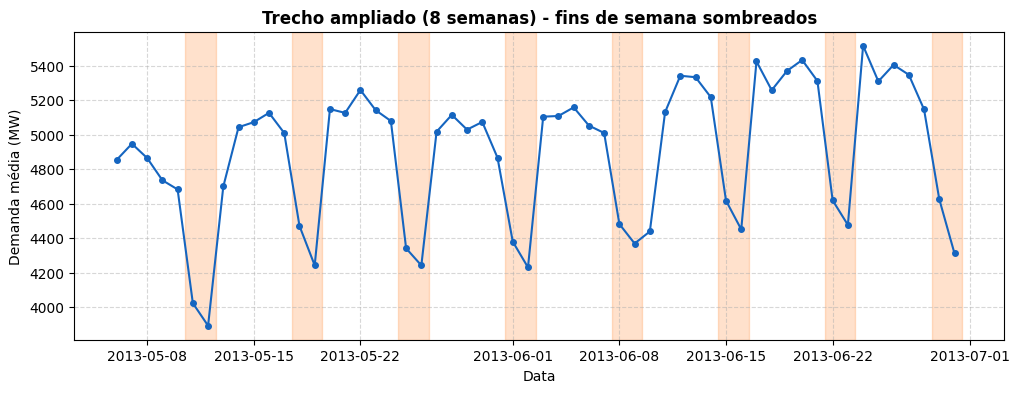

In [19]:
trecho = y_treino.loc['2013-05-06':'2013-06-30']

plt.figure(figsize=(12, 4))
plt.plot(trecho, marker='o', markersize=4, color=COR_SERIE)
for d in trecho.index[trecho.index.dayofweek == 5]:  # sombreia sábado e domingo
    plt.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=36), color=COR_DESTAQUE, alpha=0.2)
plt.title('Trecho ampliado (8 semanas) - fins de semana sombreados', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

Cai todo sábado e domingo: sazonalidade de 7 dias

- **Demanda por dia da semana (treino)**

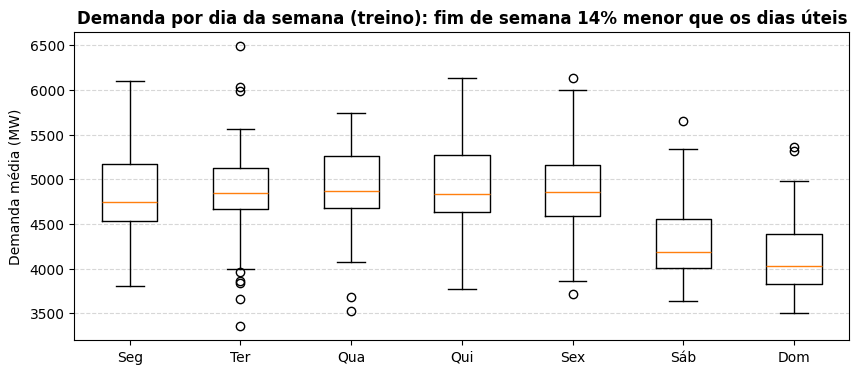

Média dos dias úteis: 4891 MW | média do fim de semana: 4200 MW


In [20]:
dia_semana = y_treino.index.dayofweek
nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

media_util = y_treino[dia_semana < 5].mean()
media_fds = y_treino[dia_semana >= 5].mean()
queda_fds = (1 - media_fds / media_util) * 100

plt.figure(figsize=(10, 4))
plt.boxplot([y_treino[dia_semana == i] for i in range(7)])
plt.xticks(range(1, 8), nomes_dias)
plt.title(f'Demanda por dia da semana (treino): fim de semana {queda_fds:.0f}% menor que os dias úteis', fontweight='bold')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5, axis='y')
plt.show()

print("Média dos dias úteis:", round(media_util), "MW | média do fim de semana:", round(media_fds), "MW")

- **Demanda por mês (treino)**: o ciclo das estações

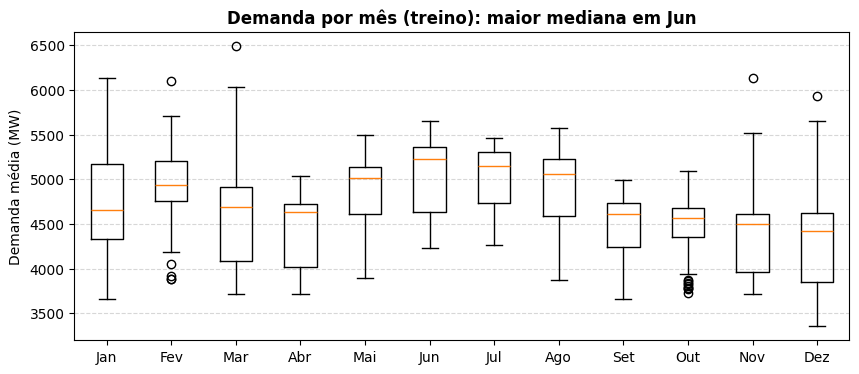

Mediana de cada mês (MW):
      Jan     Fev     Mar     Abr     Mai     Jun     Jul     Ago     Set  \
0  4659.0  4941.0  4690.0  4636.0  5010.0  5225.0  5147.0  5061.0  4616.0   

      Out     Nov     Dez  
0  4572.0  4500.0  4420.0  


In [21]:
mes = y_treino.index.month
nomes_meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
mediana_mes = y_treino.groupby(mes).median()

plt.figure(figsize=(10, 4))
plt.boxplot([y_treino[mes == m] for m in range(1, 13)])
plt.xticks(range(1, 13), nomes_meses)
plt.title(f'Demanda por mês (treino): maior mediana em {nomes_meses[mediana_mes.idxmax() - 1]}', fontweight='bold')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5, axis='y')
plt.show()

print("Mediana de cada mês (MW):")
print(pd.Series(mediana_mes.values, index=nomes_meses).round(0).to_frame().T)

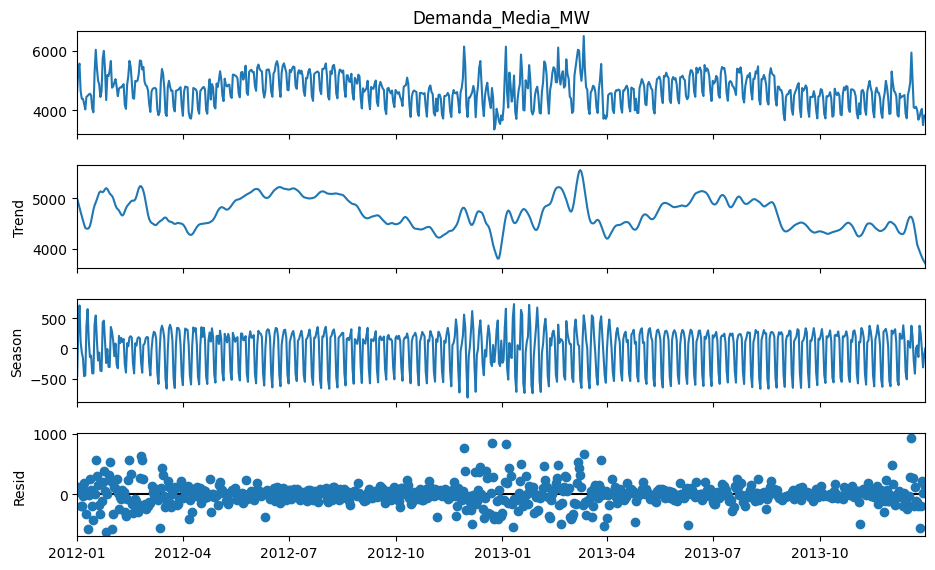

In [22]:
# Decomposicao STL com periodo de 7 dias
stl = STL(y_treino, period=7)
res = stl.fit()
fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

O ciclo das estacoes (anual) fica dentro da tendencia

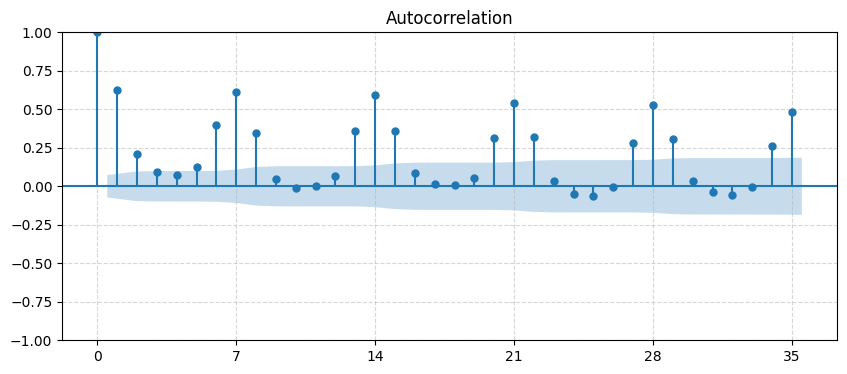

In [23]:
# ACF
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(y_treino, lags=35, ax=ax)
plt.xticks(range(0, 36, 7))
plt.grid(linestyle='--', alpha=0.5)
plt.show()

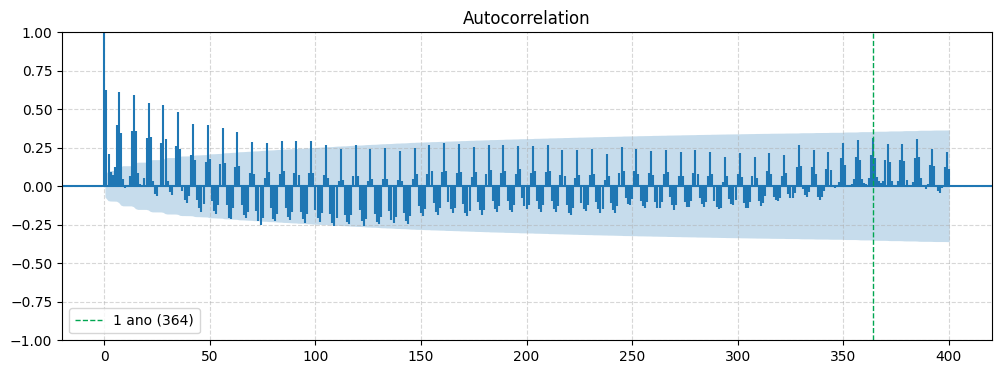

In [24]:
# ACF
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(y_treino, lags=400, ax=ax, marker='')
plt.axvline(364, color=COR_TESTE, linestyle='--', linewidth=1, label='1 ano (364)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

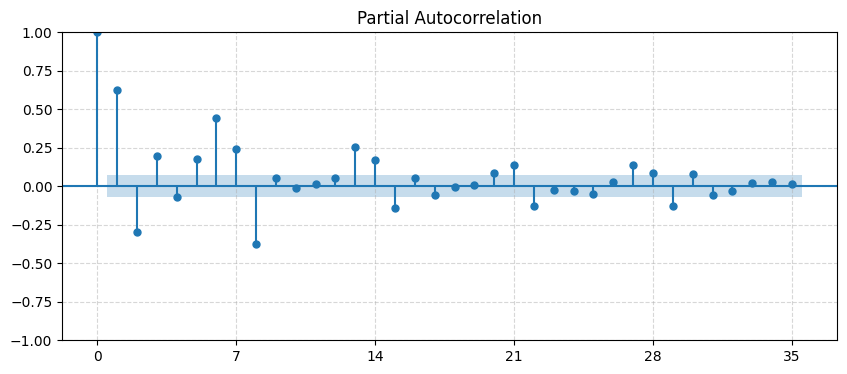

In [25]:
# PACF
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(y_treino, lags=35, ax=ax)
plt.xticks(range(0, 36, 7))
plt.grid(linestyle='--', alpha=0.5)
plt.show()

- **Teste ADF de estacionariedade**
  - **Hipótese nula do teste ADF**: `A série não é estacionária`
  - **p-value**: `É a probabilidade da estatística ocorrer (ou ser mais extrema) considerando a hipótese nula (a série não é estacionária) verdadeira`

In [26]:
adfuller(y_treino.values, result_object=True)

ADFullerResult
ADF Statistic: -2.06730
P-value: 0.25786
Used Lag: 20
Nobs: 710
Critical Values: {'1%': np.float64(-3.439593802573824), '5%': np.float64(-2.865619356068967), '10%': np.float64(-2.568942332870462)}

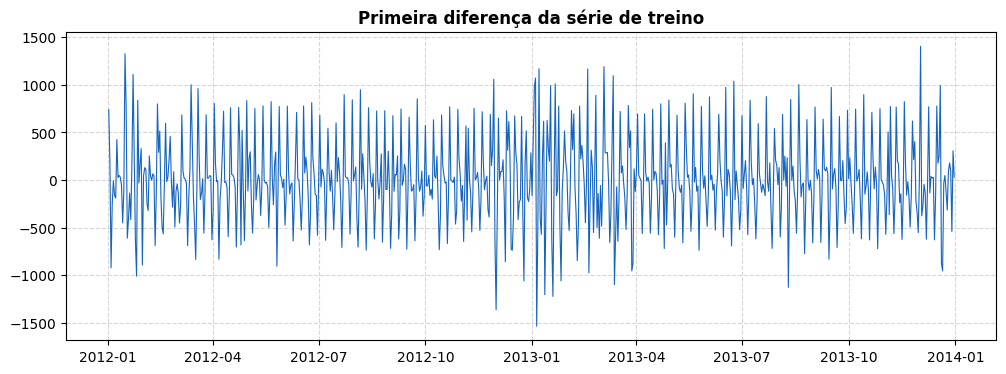

In [27]:
# Primeira diferença
plt.figure(figsize=(12, 4))
plt.plot(y_treino.diff(), color=COR_SERIE, linewidth=0.8)
plt.title('Primeira diferença da série de treino', fontweight='bold')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

In [28]:
adfuller(y_treino.diff().dropna().values, result_object=True)

ADFullerResult
ADF Statistic: -8.37024
P-value: 0.00000
Used Lag: 20
Nobs: 709
Critical Values: {'1%': np.float64(-3.439606888036868), '5%': np.float64(-2.865625121924057), '10%': np.float64(-2.5689454046801052)}

- **Teste KPSS (complemento do ADF)**
  - **Hipótese nula do KPSS**: `A série é estacionária` (o contrário do ADF)
  - Se o p-value for pequeno (≤ 0,05), rejeitamos a estacionariedade. O statsmodels limita o p-value do KPSS entre 0,01 e 0,10.

In [29]:
kpss_serie = kpss(y_treino.values, regression='c', nlags='auto')
kpss_dif = kpss(y_treino.diff().dropna().values, regression='c', nlags='auto')

print("KPSS na série original: estatística =", round(kpss_serie[0], 3), "| p-value =", kpss_serie[1])
print("KPSS na 1ª diferença:   estatística =", round(kpss_dif[0], 3), "| p-value =", kpss_dif[1])

KPSS na série original: estatística = 0.792 | p-value = 0.01
KPSS na 1ª diferença:   estatística = 0.08 | p-value = 0.1


- **Conclusão do diagnóstico**

  - **Sazonalidade de 7 dias:** forte e regular. Aparece no trecho ampliado, no boxplot por dia da semana (fim de semana **14% menor**: 4.200 x 4.891 MW), na STL e na ACF (picos em 7, 14, 21, 28). A PACF tem picos fortes nos lags 1 e 7.
  - **Ciclo das estações (1 ano):** existe. As medianas mensais vão de **4.420 MW em dezembro a 5.225 MW em junho**: o inverno (jun-ago) tem a maior demanda e fevereiro também sobe com o calor. A ACF longa volta a subir perto do lag 364. Esse ciclo **não entra como sazonalidade** em nenhum modelo: o treino da validação tem só 1 ano (2012), e um padrão que se repete uma vez por ano não pode ser estimado com uma única repetição. O Prophet o captura **de forma indireta**, pelo regressor de temperatura do ano anterior (Parte 4.5).
  - **Estacionariedade:** os dois testes concordam.
    - **Série original:** o ADF não rejeita a não estacionariedade (p = 0,26) e o KPSS rejeita a estacionariedade (p ≤ 0,01). A série **não é estacionária**.
    - **1ª diferença:** o ADF rejeita a não estacionariedade (p ≈ 0) e o KPSS não rejeita a estacionariedade (p ≥ 0,10). A 1ª diferença **é estacionária**.
    - Com só 2 anos, a "não estacionariedade" vem do **ciclo das estações**, que sobe e desce, e não de uma tendência que cresce sem parar. Por isso **d = 0 e d = 1 serão testados**, e a validação decide.

## <font color = Blue> **Parte 4 - Treinamento e seleção do modelo**

- Compare **ETSModel, ARIMA, SARIMA, árvore de decisão, Prophet e LSTM**, justificando eventual não aplicação;
- Para seleção do modelo e seus hiperparâmetros, utilize **Cross Validation Temporal exclusivamente dentro do conjunto de treino**, com as mesmas janelas para todos os candidatos e blocos de validação de comprimento **`h`**;
- Selecione pelo **RMSE médio das janelas de validação**, calculado na escala original (demanda média em MW);
- Todos os modelos devem prever os **`h` períodos a partir da mesma origem**, sem utilizar valores reais do bloco previsto. Para árvore de decisão e LSTM, explicite a estratégia de previsão (recursiva, direta ou de múltiplas saídas).

- **Janela de validação**

Como explicado na Parte 1: treina com **2012** (366 dias) e prevê **2013** (365 dias). Todos os modelos usam a **mesma janela**, preveem os 365 dias a partir da **mesma origem** (31/12/2012) e não usam nenhum valor real de 2013. O critério é o **RMSE em MW**.

In [30]:
n_inicial = 366  # 2012 tem 366 dias (ano bissexto)

cv_treino = y_treino.iloc[:n_inicial]
cv_valid = y_treino.iloc[n_inicial:n_inicial + h]

print("Treino da validação:", cv_treino.index[0].date(), "a", cv_treino.index[-1].date())
print("Validação:", cv_valid.index[0].date(), "a", cv_valid.index[-1].date())

Treino da validação: 2012-01-01 a 2012-12-31
Validação: 2013-01-01 a 2013-12-31


- **Funções de previsão**

Cada modelo tem uma função que treina numa série e devolve a previsão dos próximos `n` dias. A mesma função é usada na validação (Parte 4), no teste (Parte 5) e na previsão final (Parte 6).

Também criamos duas **referências simples**, que não entram na escolha, mas mostram se os modelos realmente aprendem algo:
- **Média:** prevê sempre a média do treino;
- **Sazonal ingênuo:** repete as últimas 52 semanas (364 dias), ou seja, prevê para cada dia o valor do **mesmo dia da semana no ano anterior**.

In [31]:
def prever_ets(serie, config, n):
    erro, tendencia, sazonal = config
    modelo = ETSModel(serie, error=erro, trend=tendencia, seasonal=sazonal, seasonal_periods=7).fit(disp=False)
    return modelo.forecast(n).values


def prever_arima(serie, config, n):
    # serve para ARIMA e SARIMA (ARIMA = sazonal (0,0,0,0))
    ordem, ordem_sazonal = config
    modelo = ARIMA(serie, order=ordem, seasonal_order=ordem_sazonal).fit()
    if not modelo.mle_retvals['converged']:  # ajuste que não convergiu fica fora da comparação
        return np.full(n, np.nan)
    return modelo.forecast(n).values


def prever_media(serie, config, n):
    return np.full(n, serie.mean())


def prever_sazonal_ingenuo(serie, config, n):
    # repete as últimas 52 semanas: mesmo dia da semana do ano anterior
    return np.resize(serie.values[-364:], n)


def calcular_rmse(real, previsto):
    if np.isnan(previsto).any():  # modelo que não convergiu
        return np.nan
    erro = root_mean_squared_error(real, previsto)
    if not np.isfinite(erro):  # previsões que explodem
        return np.nan
    return erro

### <font color = Blue> **4.1 - ETS (sazonalidade de 7 dias)**

Grade completa de erro {A, M} x tendência {N, A, M} x sazonalidade {N, A, M}, com `seasonal_periods = 7` (18 modelos).

In [32]:
error_opts = ['add', 'mul']
trend_opts = [None, 'add', 'mul']
seasonal_opts = [None, 'add', 'mul']

resultados = []
for e in error_opts:
    for t in trend_opts:
        for s in seasonal_opts:
            nome = f"ETS({e[0].upper()},{'N' if t is None else t[0].upper()},{'N' if s is None else s[0].upper()})"
            try:
                previsao = prever_ets(cv_treino, (e, t, s), h)
                rmse = calcular_rmse(cv_valid, previsao)
            except Exception:
                rmse = np.nan
            resultados.append({'Modelo': nome, 'config': (e, t, s), 'RMSE': rmse})

Tabela_ets = pd.DataFrame(resultados).sort_values('RMSE')
Tabela_ets[['Modelo', 'RMSE']].head(5).round(1)

,Modelo,RMSE
16,"ETS(M,M,A)",684.2
17,"ETS(M,M,M)",727.4
10,"ETS(M,N,A)",868.1
1,"ETS(A,N,A)",868.8
0,"ETS(A,N,N)",912.9


### <font color = Blue> **4.2 - ARIMA (sem sazonalidade)**

Busca em laço: p e q de 0 até 2 (`p_max = q_max = 2`), d de 0 a 1. Serve de **referência** sem sazonalidade. Ajustes que **não convergem** ficam sem RMSE e saem da comparação.

In [33]:
p_max = 2
q_max = 2
d_max = 1

resultados = []
for p in range(p_max + 1):
    for d in range(d_max + 1):
        for q in range(q_max + 1):
            config = ((p, d, q), (0, 0, 0, 0))
            try:
                previsao = prever_arima(cv_treino, config, h)
                rmse = calcular_rmse(cv_valid, previsao)
            except Exception:
                rmse = np.nan
            resultados.append({'Modelo': f'ARIMA({p},{d},{q})', 'config': config, 'RMSE': rmse})

Tabela_arima = pd.DataFrame(resultados).sort_values('RMSE')
print("Modelos sem RMSE (não convergiram ou falharam):", Tabela_arima.RMSE.isna().sum(), "de", len(Tabela_arima))
Tabela_arima[['Modelo', 'RMSE']].head(5).round(1)

Modelos sem RMSE (não convergiram ou falharam): 0 de 18


,Modelo,RMSE
12,"ARIMA(2,0,0)",532.0
7,"ARIMA(1,0,1)",532.4
13,"ARIMA(2,0,1)",532.4
2,"ARIMA(0,0,2)",532.5
6,"ARIMA(1,0,0)",532.8


### <font color = Blue> **4.3 - SARIMA (s = 7)**

Mesma busca, agora com a parte sazonal: p e q de 0 até 2, d de 0 a 1 e P, D, Q de 0 a 1 com `s = 7` (144 modelos). A busca é feita num laço próprio porque a escolha é pelo **RMSE da validação**, e não por um critério de informação como o AIC.

In [34]:
P_max = 1
D_max = 1
Q_max = 1

resultados = []
for p in range(p_max + 1):
    for d in range(d_max + 1):
        for q in range(q_max + 1):
            for P in range(P_max + 1):
                for D in range(D_max + 1):
                    for Q in range(Q_max + 1):
                        config = ((p, d, q), (P, D, Q, 7))
                        try:
                            previsao = prever_arima(cv_treino, config, h)
                            rmse = calcular_rmse(cv_valid, previsao)
                        except Exception:
                            rmse = np.nan
                        resultados.append({'Modelo': f'SARIMA({p},{d},{q})({P},{D},{Q})[7]', 'config': config, 'RMSE': rmse})

Tabela_sarima = pd.DataFrame(resultados).sort_values('RMSE')
print("Modelos sem RMSE (não convergiram ou falharam):", Tabela_sarima.RMSE.isna().sum(), "de", len(Tabela_sarima))
Tabela_sarima[['Modelo', 'RMSE']].head(5).round(1)

Modelos sem RMSE (não convergiram ou falharam): 7 de 144


,Modelo,RMSE
53,"SARIMA(1,0,0)(1,0,1)[7]",414.2
109,"SARIMA(2,0,1)(1,0,1)[7]",489.7
101,"SARIMA(2,0,0)(1,0,1)[7]",494.9
21,"SARIMA(0,0,2)(1,0,1)[7]",510.6
55,"SARIMA(1,0,0)(1,1,1)[7]",513.0


- **Parâmetros do melhor SARIMA** (ajustado em 2012, o treino da validação)

In [35]:
config_sarima = Tabela_sarima.iloc[0]['config']
ajuste_sarima = ARIMA(cv_treino, order=config_sarima[0], seasonal_order=config_sarima[1]).fit()

print("Convergiu:", ajuste_sarima.mle_retvals['converged'])
ajuste_sarima.params.round(3)

Convergiu: True


,0
const,4736.076
ar.L1,0.784
ar.S.L7,1.000
ma.S.L7,-0.989
sigma2,64918.826


- **Por que não D = 1 (nem d = 1)?** Comparação com os melhores SARIMA que usam diferenciação

Melhor com D = 0: SARIMA(1,0,0)(1,0,1)[7] -> RMSE = 414.2 MW
Melhor com D = 1: SARIMA(1,0,0)(1,1,1)[7] -> RMSE = 513.0 MW
Melhor com d = 1: SARIMA(2,1,1)(1,0,0)[7] -> RMSE = 533.9 MW
Média prevista para 2013 -> D = 0: 4714 MW | D = 1: 4359 MW | real: 4650 MW
Média da última semana de 2012 (festas): 3686 MW


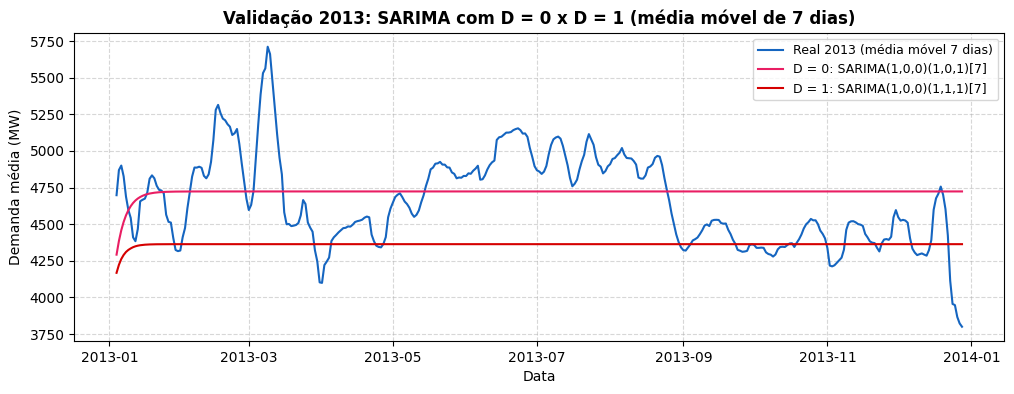

In [36]:
com_D1 = Tabela_sarima[Tabela_sarima['config'].apply(lambda c: c[1][1] == 1)]
melhor_D1 = com_D1.iloc[0]

prev_D0 = prever_arima(cv_treino, config_sarima, h)
prev_D1 = prever_arima(cv_treino, melhor_D1['config'], h)

print("Melhor com D = 0:", Tabela_sarima.iloc[0]['Modelo'], "-> RMSE =", round(Tabela_sarima.iloc[0]['RMSE'], 1), "MW")
print("Melhor com D = 1:", melhor_D1['Modelo'], "-> RMSE =", round(melhor_D1['RMSE'], 1), "MW")

com_d1 = Tabela_sarima[Tabela_sarima['config'].apply(lambda c: c[0][1] == 1)]
print("Melhor com d = 1:", com_d1.iloc[0]['Modelo'], "-> RMSE =", round(com_d1.iloc[0]['RMSE'], 1), "MW")
print("Média prevista para 2013 -> D = 0:", round(prev_D0.mean()), "MW | D = 1:", round(prev_D1.mean()), "MW | real:", round(cv_valid.mean()), "MW")
print("Média da última semana de 2012 (festas):", round(cv_treino.iloc[-7:].mean()), "MW")

plt.figure(figsize=(12, 4))
plt.plot(cv_valid.index, cv_valid.rolling(7, center=True).mean(), color=COR_SERIE, linewidth=1.5, label='Real 2013 (média móvel 7 dias)')
plt.plot(cv_valid.index, pd.Series(prev_D0).rolling(7, center=True).mean(), color=COR_SARIMA, linewidth=1.5, label=f"D = 0: {Tabela_sarima.iloc[0]['Modelo']}")
plt.plot(cv_valid.index, pd.Series(prev_D1).rolling(7, center=True).mean(), color=COR_ALERTA, linewidth=1.5, label=f"D = 1: {melhor_D1['Modelo']}")
plt.title('Validação 2013: SARIMA com D = 0 x D = 1 (média móvel de 7 dias)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9)
plt.show()

- **Leitura dos parâmetros e da comparação com a diferenciação**

  - **AR sazonal = 1,00 e MA sazonal = −0,99:** os dois praticamente se cancelam. Na prática o modelo aprende um **perfil fixo da semana** (cada dia da semana com o seu nível) em torno de uma constante, e o AR(1) = 0,78 só ajusta os primeiros dias depois da origem. O AR sazonal no limite (1,00) significa que o padrão semanal **não se apaga** com o tempo, o que é coerente com a Parte 3. O ajuste **convergiu**.
  - **Por que não D = 1:** o melhor modelo com diferença sazonal, SARIMA(1,0,0)(1,1,1)[7], teve **513 MW**, contra **414 MW**. Com D = 1 o modelo não tem constante e o nível da previsão fica preso à **última semana do treino**, que é a semana das festas de 2012 (média de 3.686 MW). Por isso ele prevê 2013 inteiro em torno de **4.359 MW**, contra 4.650 MW reais. Com D = 0, a constante puxa a previsão para a média (4.714 MW).
  - **Por que não d = 1:** o melhor SARIMA com d = 1 também ficou bem acima (cerca de **534 MW**). Tratar o ciclo das estações como uma tendência aleatória faz a previsão seguir o nível do fim de 2012.
  - **Vencedor isolado:** o 2º melhor SARIMA ficou em 490 MW, **75 MW acima**. Um vencedor tão isolado pode ser sorte da única janela de validação, então ele precisa ser confirmado **fora dela**: nos resíduos e no teste (Parte 5).

### <font color = Blue> **4.4 - Árvore de Decisão**

A árvore usa os **últimos `p` valores** (lags) como variáveis de entrada. Para cobrir o padrão semanal, testamos `p` = 7, 14 e 21, e profundidade de 1 a 10.

- **Estratégia de previsão: recursiva.** A árvore prevê o dia seguinte, esse valor previsto entra como lag e o processo se repete até completar os 365 dias.

In [37]:
def prever_arvore(serie, config, n):
    p, profundidade = config

    # Preparando a serie (lags)
    dados = pd.DataFrame({'y': serie})
    for i in range(p):
        dados[f'X_{i+1}'] = dados.y.shift(i + 1)
    dados.dropna(inplace=True)

    X = dados.drop('y', axis=1)
    y = dados.y
    modelo = DecisionTreeRegressor(random_state=42, max_depth=profundidade).fit(X, y)

    # Previsao recursiva: X_1 e o ultimo valor conhecido
    lags = list(serie.values[-p:][::-1])
    previsoes = []
    for _ in range(n):
        x_next = pd.DataFrame([lags], columns=X.columns)
        y_pred = modelo.predict(x_next)[0]
        previsoes.append(y_pred)
        lags = [y_pred] + lags[:-1]  # o previsto entra na frente
    return np.array(previsoes)


resultados = []
for p in [7, 14, 21]:
    for profundidade in range(1, 11):
        previsao = prever_arvore(cv_treino, (p, profundidade), h)
        resultados.append({'Modelo': f'Árvore (p={p}, prof.={profundidade})', 'config': (p, profundidade),
                           'RMSE': calcular_rmse(cv_valid, previsao)})

Tabela_arvore = pd.DataFrame(resultados).sort_values('RMSE')
Tabela_arvore[['Modelo', 'RMSE']].head(5).round(1)

,Modelo,RMSE
27,"Árvore (p=21, prof.=8)",492.6
26,"Árvore (p=21, prof.=7)",500.4
24,"Árvore (p=21, prof.=5)",504.4
23,"Árvore (p=21, prof.=4)",508.5
28,"Árvore (p=21, prof.=9)",537.8


### <font color = Blue> **4.5 - Prophet**

O Prophet usa o formato `ds` (data) e `y` (valor). Configuração:
- `weekly_seasonality=True` e `yearly_seasonality=False` (só a sazonalidade de 7 dias);
- `seasonality_mode`: aditivo ou multiplicativo;
- `changepoint_prior_scale`: flexibilidade da tendência (0.001, 0.01, 0.05, 0.5);
- **Datas especiais:** com e sem o período de festas (24/12 a 02/01) como feriado, o termo $h(t)$ da fórmula do Prophet;
- **Regressor de temperatura:** sem regressor, ou com a temperatura como variável extra (`add_regressor`), diária ou suavizada por média móvel de **7, 14 ou 30 dias**, em dois formatos:
  - **|z| (um regressor):** distância da temperatura à média, sem separar frio de calor. Obriga o frio e o calor a terem o **mesmo efeito** na demanda;
  - **frio + calor (dois regressores):** $z_{frio} = \max(0, -z)$ e $z_{calor} = \max(0, z)$, com $z_{frio} + z_{calor} = |z|$. Cada lado do "U" ganha o **seu próprio coeficiente**. É a ideia dos graus-dia de aquecimento e de resfriamento usada no setor elétrico.

**Como o regressor é montado (sem olhar o futuro):**
- **Base fixa:** a média e o desvio padrão da temperatura do **1º ano (2012)** são calculados uma vez e usados como base para sempre: $|z_t| = |T_t - \bar{T}_{2012}| \,/\, s_{2012}$. Ele mede o quanto o dia está longe de uma temperatura "confortável" (frio ou calor aumentam a demanda, o formato em "U" da Parte 2).
- **No período ajustado (histórico):** usa o |z| do **próprio dia**, que já é conhecido.
- **No período previsto:** a temperatura real ainda não existe, então usa o |z| da **mesma data do ano anterior** como estimativa. Ex.: para prever 15/07/2013 usa a temperatura de 15/07/2012.
- **Por que separar frio e calor:** no inverno (jun-ago) o frio é **constante** e quase todo dia liga aquecimento, então a demanda sobe a estação inteira. No verão o calor só pesa nas **ondas de calor**, que são poucos dias. Com um único |z| o modelo tira uma média dos dois efeitos e **subestima o inverno**.
- **Suavização:** o |z| de um dia específico do ano anterior é muito ruidoso (correlação de só 0,14 com a demanda, Parte 2). A média móvel tira o ruído de cada dia e deixa o **ciclo das estações** (inverno e verão mais longe do conforto). A média é **só para trás** (dias já ocorridos), igual no ajuste e na previsão, para não usar nenhuma temperatura posterior à origem.

In [38]:
# Periodo de festas como feriado do Prophet (24/12 + 9 dias = ate 02/01)
festas = pd.DataFrame({
    'holiday': 'festas',
    'ds': pd.to_datetime(['2011-12-24', '2012-12-24', '2013-12-24', '2014-12-24', '2015-12-24']),
    'lower_window': 0,
    'upper_window': 9
})

# |z-score| da temperatura com base FIXA no 1º ano (2012): mesma média e desvio para sempre
media_temp_base = df.loc['2012', 'Temperatura_Media'].mean()
desvio_temp_base = df.loc['2012', 'Temperatura_Media'].std()
z_temp = (df['Temperatura_Media'] - media_temp_base) / desvio_temp_base
series_temp = {'abs_z_temp': z_temp.abs(),          # |z|: frio e calor juntos
               'z_frio': (-z_temp).clip(lower=0),   # so abaixo da media (inverno)
               'z_calor': z_temp.clip(lower=0)}     # so acima da media (verao)
REGRESSORES = {'abs': ['abs_z_temp'], 'frio_calor': ['z_frio', 'z_calor']}
print(f"Base da temperatura (2012): média = {media_temp_base:.2f} °C | desvio = {desvio_temp_base:.2f} °C")


def temp_suave(nome, janela):
    # media movel so para tras (janela = 1 -> diario, sem suavizar)
    return series_temp[nome].rolling(janela, min_periods=1).mean()


def temp_mesmo_dia(datas, janela=1, nome='abs_z_temp'):
    # historico: valor do proprio dia (ja conhecido)
    return temp_suave(nome, janela).reindex(datas).values


def temp_ano_anterior(datas, janela=1, nome='abs_z_temp'):
    # futuro: valor da mesma data do ano anterior (29/02 sem par cai no dia vizinho)
    valores = temp_suave(nome, janela).reindex(datas - pd.DateOffset(years=1))
    return valores.ffill().bfill().values


# nomes antigos (usados nos graficos)
def abs_z_mesmo_dia(datas, janela=1):
    return temp_mesmo_dia(datas, janela, 'abs_z_temp')


def abs_z_ano_anterior(datas, janela=1):
    return temp_ano_anterior(datas, janela, 'abs_z_temp')


def regressores_futuro(datas, config):
    # tabela com os regressores de temperatura para datas previstas (ano anterior)
    _, _, _, janela_temp, tipo_temp = config
    tabela = pd.DataFrame(index=datas)
    if janela_temp:
        for nome in REGRESSORES[tipo_temp]:
            tabela[nome] = temp_ano_anterior(datas, janela_temp, nome)
    return tabela


def prever_prophet(serie, config, n, intervalo=False, retornar_modelo=False):
    modo, cps, usar_festas, janela_temp, tipo_temp = config  # janela_temp: 0 = sem regressor
    dados = pd.DataFrame({'ds': serie.index, 'y': serie.values})
    modelo = Prophet(seasonality_mode=modo, daily_seasonality=False, weekly_seasonality=True,
                     yearly_seasonality=False, changepoint_prior_scale=cps,
                     holidays=festas if usar_festas else None, interval_width=0.95)
    if janela_temp:
        for nome in REGRESSORES[tipo_temp]:
            dados[nome] = temp_mesmo_dia(serie.index, janela_temp, nome)
            modelo.add_regressor(nome)
    modelo.fit(dados)
    futuro = modelo.make_future_dataframe(periods=n, freq='D', include_history=False)
    if janela_temp:
        futuro = futuro.join(regressores_futuro(pd.DatetimeIndex(futuro['ds']), config).reset_index(drop=True))
    np.random.seed(42)  # o intervalo do prophet usa simulacao
    previsao = modelo.predict(futuro)
    if retornar_modelo:
        return modelo, previsao
    if intervalo:
        return previsao
    return previsao.yhat.values


resultados = []
for modo in ['additive', 'multiplicative']:
    for cps in [0.001, 0.01, 0.05, 0.5]:
        for usar_festas in [False, True]:
            opcoes_temp = [(0, None)] + [(j, t) for t in ['abs', 'frio_calor'] for j in [1, 7, 14, 30]]
            for janela_temp, tipo_temp in opcoes_temp:
                config = (modo, cps, usar_festas, janela_temp, tipo_temp)
                previsao = prever_prophet(cv_treino, config, h)
                rotulo = '|z|' if tipo_temp == 'abs' else 'frio+calor'
                temp = ('sem temp.' if janela_temp == 0 else f'{rotulo} diário' if janela_temp == 1
                        else f'{rotulo} MM{janela_temp}')
                nome = f"Prophet ({modo}, cps={cps}, {'com' if usar_festas else 'sem'} festas, {temp})"
                resultados.append({'Modelo': nome, 'config': config,
                                   'RMSE': calcular_rmse(cv_valid, previsao)})

Tabela_prophet = pd.DataFrame(resultados).sort_values('RMSE')
Tabela_prophet[['Modelo', 'RMSE']].head(5).round(1)

Base da temperatura (2012): média = 15.95 °C | desvio = 4.73 °C


,Modelo,RMSE
13,"Prophet (additive, cps=0.001, com festas, |z| ...",366.5
85,"Prophet (multiplicative, cps=0.001, com festas...",371.3
12,"Prophet (additive, cps=0.001, com festas, |z| ...",371.7
84,"Prophet (multiplicative, cps=0.001, com festas...",376.6
11,"Prophet (additive, cps=0.001, com festas, |z| ...",389.1


In [39]:
# Efeito do regressor: melhor configuração para cada opção de temperatura
opcao_cfg = Tabela_prophet['config'].apply(lambda cfg: (cfg[3], cfg[4]))

linhas = []
for j, t in [(0, None)] + [(j, t) for t in ['abs', 'frio_calor'] for j in [1, 7, 14, 30]]:
    sub = Tabela_prophet[opcao_cfg == (j, t)]
    if j == 0:
        rotulo = 'sem regressor'
    else:
        rotulo = ('|z|' if t == 'abs' else 'frio + calor') + (' diário' if j == 1 else f' MM{j}')
    linhas.append({'Temperatura': rotulo, 'Melhor modelo': sub.iloc[0]['Modelo'], 'RMSE': sub.iloc[0]['RMSE']})

efeito_temp = pd.DataFrame(linhas)
efeito_temp.round(1)

,Temperatura,Melhor modelo,RMSE
0,sem regressor,"Prophet (multiplicative, cps=0.001, com festas...",420.4
1,|z| diário,"Prophet (multiplicative, cps=0.001, com festas...",431.4
2,|z| MM7,"Prophet (additive, cps=0.001, com festas, |z| ...",389.1
3,|z| MM14,"Prophet (additive, cps=0.001, com festas, |z| ...",371.7
4,|z| MM30,"Prophet (additive, cps=0.001, com festas, |z| ...",366.5
5,frio + calor diário,"Prophet (additive, cps=0.5, com festas, frio+c...",447.4
6,frio + calor MM7,"Prophet (additive, cps=0.01, com festas, frio+...",406.8
7,frio + calor MM14,"Prophet (multiplicative, cps=0.01, com festas,...",410.0
8,frio + calor MM30,"Prophet (multiplicative, cps=0.05, sem festas,...",426.3


- **Regressor na validação: |z| diário** (o que o modelo recebe x o que aconteceu de verdade em 2013)

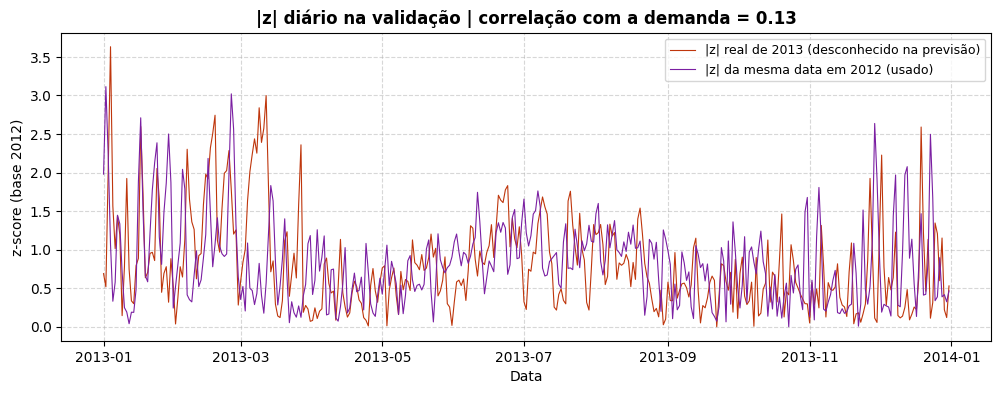

In [40]:
datas_valid = cv_valid.index
r = np.corrcoef(cv_valid.values, abs_z_ano_anterior(datas_valid, 1))[0, 1]

plt.figure(figsize=(12, 4))
plt.plot(datas_valid, abs_z_mesmo_dia(datas_valid, 1), color=COR_TEMP, linewidth=0.8, label='|z| real de 2013 (desconhecido na previsão)')
plt.plot(datas_valid, abs_z_ano_anterior(datas_valid, 1), color=COR_PROPHET, linewidth=0.8, label='|z| da mesma data em 2012 (usado)')
plt.title(f'|z| diário na validação | correlação com a demanda = {r:.2f}', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('z-score (base 2012)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9)
plt.show()

- **Regressor na validação: |z| suavizado (média móvel de 30 dias)**

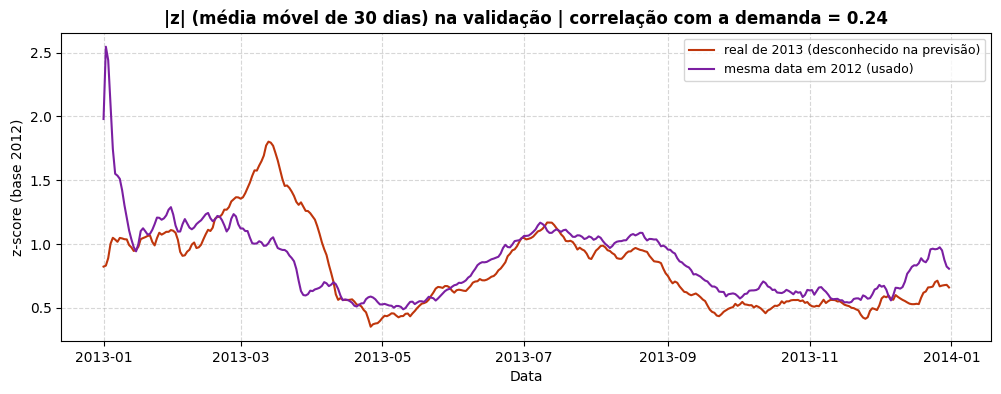

In [41]:
usado = temp_ano_anterior(datas_valid, 30, 'abs_z_temp')
r = np.corrcoef(cv_valid.values, usado)[0, 1]

plt.figure(figsize=(12, 4))
plt.plot(datas_valid, temp_mesmo_dia(datas_valid, 30, 'abs_z_temp'), color=COR_TEMP, linewidth=1.5, label='real de 2013 (desconhecido na previsão)')
plt.plot(datas_valid, usado, color=COR_PROPHET, linewidth=1.5, label='mesma data em 2012 (usado)')
plt.title(f'|z| (média móvel de 30 dias) na validação | correlação com a demanda = {r:.2f}', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('z-score (base 2012)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9)
plt.show()

- **Regressor na validação: frio suavizado (média móvel de 30 dias)**

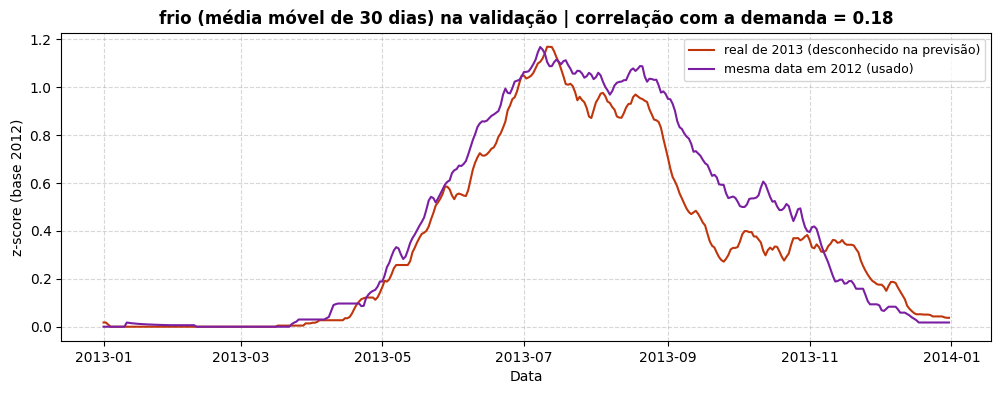

In [42]:
usado = temp_ano_anterior(datas_valid, 30, 'z_frio')
r = np.corrcoef(cv_valid.values, usado)[0, 1]

plt.figure(figsize=(12, 4))
plt.plot(datas_valid, temp_mesmo_dia(datas_valid, 30, 'z_frio'), color=COR_TEMP, linewidth=1.5, label='real de 2013 (desconhecido na previsão)')
plt.plot(datas_valid, usado, color=COR_PROPHET, linewidth=1.5, label='mesma data em 2012 (usado)')
plt.title(f'frio (média móvel de 30 dias) na validação | correlação com a demanda = {r:.2f}', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('z-score (base 2012)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9)
plt.show()

- **Regressor na validação: calor suavizado (média móvel de 30 dias)**

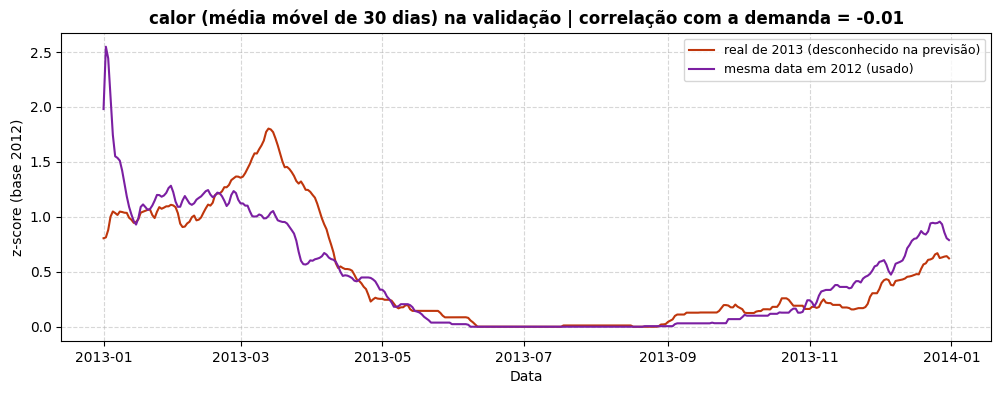

In [43]:
usado = temp_ano_anterior(datas_valid, 30, 'z_calor')
r = np.corrcoef(cv_valid.values, usado)[0, 1]

plt.figure(figsize=(12, 4))
plt.plot(datas_valid, temp_mesmo_dia(datas_valid, 30, 'z_calor'), color=COR_TEMP, linewidth=1.5, label='real de 2013 (desconhecido na previsão)')
plt.plot(datas_valid, usado, color=COR_PROPHET, linewidth=1.5, label='mesma data em 2012 (usado)')
plt.title(f'calor (média móvel de 30 dias) na validação | correlação com a demanda = {r:.2f}', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('z-score (base 2012)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9)
plt.show()

- **Validação 2013: melhor |z| x melhor frio + calor** (nível, média móvel de 7 dias)

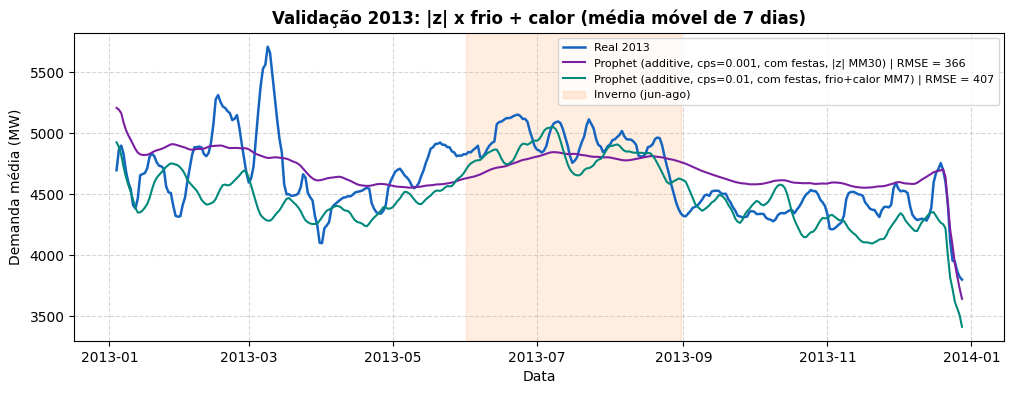

In [44]:
melhor_abs = Tabela_prophet[opcao_cfg.apply(lambda o: o[1] == 'abs')].iloc[0]
melhor_fc = Tabela_prophet[opcao_cfg.apply(lambda o: o[1] == 'frio_calor')].iloc[0]

plt.figure(figsize=(12, 4))
plt.plot(datas_valid, cv_valid.rolling(7, center=True).mean(), color=COR_SERIE, linewidth=1.8, label='Real 2013')
for linha, cor in [(melhor_abs, COR_PROPHET), (melhor_fc, '#00897B')]:
    p = pd.Series(prever_prophet(cv_treino, linha['config'], h), index=datas_valid)
    plt.plot(p.rolling(7, center=True).mean(), color=cor, linewidth=1.5, label=f"{linha['Modelo']} | RMSE = {linha['RMSE']:.0f}")
plt.axvspan(pd.Timestamp('2013-06-01'), pd.Timestamp('2013-08-31'), color=COR_DESTAQUE, alpha=0.12, label='Inverno (jun-ago)')
plt.title('Validação 2013: |z| x frio + calor (média móvel de 7 dias)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=8)
plt.show()

- **Teste extra: e se o Prophet usasse a sazonalidade anual?**

Sem a sazonalidade anual, a única coisa que o Prophet deixa variar ao longo do ano é a **tendência**, que é uma **reta**. Por isso a previsão dele sai "linear" (reta + padrão semanal + festas) e não sobe no inverno. Para fazer uma curva ao longo do ano, seria preciso ligar `yearly_seasonality=True`. Testamos na mesma validação:

In [45]:
for cps in [0.001, 0.05]:
    dados = pd.DataFrame({'ds': cv_treino.index, 'y': cv_treino.values})
    modelo = Prophet(seasonality_mode='multiplicative', daily_seasonality=False, weekly_seasonality=True,
                     yearly_seasonality=True, changepoint_prior_scale=cps, holidays=festas).fit(dados)
    futuro = modelo.make_future_dataframe(periods=h, freq='D', include_history=False)
    previsao = modelo.predict(futuro).yhat.values
    print("Prophet COM sazonalidade anual, cps =", cps, "-> RMSE =", round(calcular_rmse(cv_valid, previsao), 1), "MW")

Prophet COM sazonalidade anual, cps = 0.001 -> RMSE = 855.9 MW
Prophet COM sazonalidade anual, cps = 0.05 -> RMSE = 931.6 MW


- O próprio Prophet avisa que a sazonalidade anual precisa de uns **2 anos de histórico**, e a janela de validação tem só **1 ano (2012)**. Com 1 ano ele não consegue separar o que é tendência do que é estação, e o erro dispara (bem acima dos 366 MW da melhor versão só com 7 dias e temperatura).
- Pela regra do enunciado (escolher pela validação), a versão anual **não pode ser validada** neste trabalho. Por isso o Prophet fica com a sazonalidade de 7 dias, como os outros modelos.

### <font color = Blue> **4.6 - LSTM**

Arquitetura: `LSTM(32)` + `Dense(1)`, otimizador `adam`, perda `mse`, `batch_size=16`, com MinMaxScaler e janelas deslizantes. Testamos:
- **Transformação:** diferença sazonal de 7 dias ou a série no nível original;
- **Janela** (`window_size`): 7 e 14 dias;
- **Épocas:** 10 e 20.

- **Estratégia de previsão: recursiva.** Cada valor previsto entra na janela para prever o próximo, até completar os 365 dias.
- `tf.keras.utils.set_random_seed(42)` fixa a aleatoriedade. Mesmo assim, o resultado pode variar um pouco em outra máquina (ex.: Colab).

In [46]:
# Cria as janelas deslizantes: entrada = window_size dias, saída = dia seguinte
def create_dataset(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])
    return np.array(X), np.array(y)


def prever_lstm(serie, config, n):
    transformacao, window_size, epocas = config
    tf.keras.utils.set_random_seed(42)  # repetibilidade

    if transformacao == 'diferença 7 dias':
        base = serie.diff(7).dropna()
    else:
        base = serie

    scaler = MinMaxScaler(feature_range=(0, 1))
    serie_scaled = scaler.fit_transform(base.to_numpy().reshape(-1, 1))

    X, y = create_dataset(serie_scaled, window_size)
    X = X.reshape((X.shape[0], X.shape[1], 1))

    model = Sequential([Input(shape=(window_size, 1)), LSTM(units=32, activation='tanh'), Dense(1)])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X, y, epochs=epocas, batch_size=16, verbose=0)

    # Previsao recursiva
    janela = serie_scaled[-window_size:].reshape(1, window_size, 1)
    previsoes = []
    for _ in range(n):
        proximo = model.predict(janela, verbose=0)
        previsoes.append(proximo[0, 0])
        janela = np.append(janela[:, 1:, :], proximo.reshape(1, 1, 1), axis=1)
    previsoes = scaler.inverse_transform(np.array(previsoes).reshape(-1, 1)).ravel()

    # Desfazendo a diferenca de 7 dias
    if transformacao == 'diferença 7 dias':
        niveis = list(serie.values[-7:])
        for i, dif in enumerate(previsoes):
            niveis.append(niveis[i] + dif)
        previsoes = np.array(niveis[7:])
    return previsoes


resultados = []
for transformacao in ['diferença 7 dias', 'nível']:
    for window_size in [7, 14]:
        for epocas in [10, 20]:
            config = (transformacao, window_size, epocas)
            previsao = prever_lstm(cv_treino, config, h)
            resultados.append({'Modelo': f'LSTM ({transformacao}, janela={window_size}, épocas={epocas})',
                               'config': config, 'RMSE': calcular_rmse(cv_valid, previsao)})

Tabela_lstm = pd.DataFrame(resultados).sort_values('RMSE')
Tabela_lstm[['Modelo', 'RMSE']].round(1)

,Modelo,RMSE
4,"LSTM (nível, janela=7, épocas=10)",543.6
6,"LSTM (nível, janela=14, épocas=10)",550.2
5,"LSTM (nível, janela=7, épocas=20)",566.2
7,"LSTM (nível, janela=14, épocas=20)",638.9
1,"LSTM (diferença 7 dias, janela=7, épocas=20)",1287.3
0,"LSTM (diferença 7 dias, janela=7, épocas=10)",1864.1
3,"LSTM (diferença 7 dias, janela=14, épocas=20)",5331.3
2,"LSTM (diferença 7 dias, janela=14, épocas=10)",5482.8


### <font color = Blue> **4.7 - Comparação e escolha do modelo**

In [47]:
# Melhor configuracao
melhores = {
    'ETS': (prever_ets, Tabela_ets.iloc[0]),
    'ARIMA': (prever_arima, Tabela_arima.iloc[0]),
    'SARIMA': (prever_arima, Tabela_sarima.iloc[0]),
    'Árvore': (prever_arvore, Tabela_arvore.iloc[0]),
    'Prophet': (prever_prophet, Tabela_prophet.iloc[0]),
    'LSTM': (prever_lstm, Tabela_lstm.iloc[0]),
}

comparacao = pd.DataFrame([{'Família': familia, 'Modelo': linha['Modelo'], 'RMSE validação': linha['RMSE']}
                           for familia, (funcao, linha) in melhores.items()])
comparacao = comparacao.sort_values('RMSE validação').reset_index(drop=True)
comparacao.round(1)

,Família,Modelo,RMSE validação
0,Prophet,"Prophet (additive, cps=0.001, com festas, |z| ...",366.5
1,SARIMA,"SARIMA(1,0,0)(1,0,1)[7]",414.2
2,Árvore,"Árvore (p=21, prof.=8)",492.6
3,ARIMA,"ARIMA(2,0,0)",532.0
4,LSTM,"LSTM (nível, janela=7, épocas=10)",543.6
5,ETS,"ETS(M,M,A)",684.2


- **Referências simples na validação** (não entram na escolha)

In [48]:
referencias = {'Média': prever_media, 'Sazonal ingênuo': prever_sazonal_ingenuo}

ref_validacao = {}
for nome, funcao in referencias.items():
    ref_validacao[nome] = calcular_rmse(cv_valid, funcao(cv_treino, None, h))
    print(f"{nome}: RMSE na validação = {ref_validacao[nome]:.1f} MW")

Média: RMSE na validação = 534.5 MW
Sazonal ingênuo: RMSE na validação = 455.3 MW


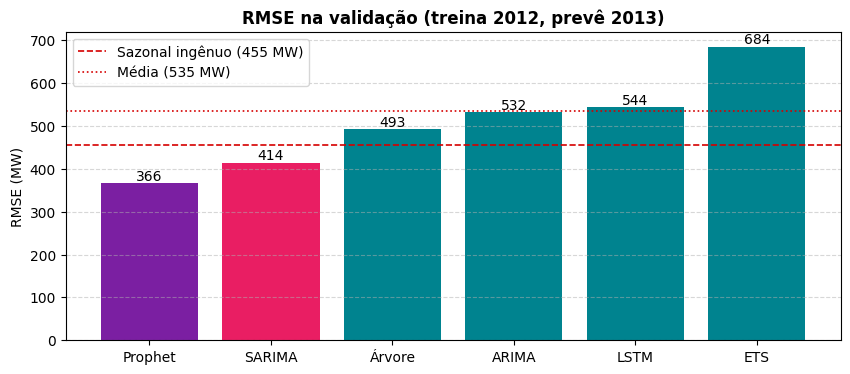

In [49]:
cores = [COR_SARIMA if f == 'SARIMA' else COR_PROPHET if f == 'Prophet' else COR_OUTROS for f in comparacao['Família']]

plt.figure(figsize=(10, 4))
barras = plt.bar(comparacao['Família'], comparacao['RMSE validação'], color=cores)
plt.bar_label(barras, fmt='%.0f')
plt.axhline(ref_validacao['Sazonal ingênuo'], color=COR_ALERTA, linestyle='--', linewidth=1.2,
            label=f"Sazonal ingênuo ({ref_validacao['Sazonal ingênuo']:.0f} MW)")
plt.axhline(ref_validacao['Média'], color=COR_ALERTA, linestyle=':', linewidth=1.2,
            label=f"Média ({ref_validacao['Média']:.0f} MW)")
plt.title('RMSE na validação (treina 2012, prevê 2013)', fontweight='bold')
plt.ylabel('RMSE (MW)')
plt.grid(linestyle='--', alpha=0.5, axis='y')
plt.legend(loc='upper left')
plt.show()

- **Previsões de 2013 de cada família** (um gráfico por modelo, na ordem da validação)

In [50]:
# Previsões de 2013
prev_validacao = {}
for familia, (funcao, linha) in melhores.items():
    prev_validacao[familia] = funcao(cv_treino, linha['config'], h)

rmse_val = comparacao.set_index('Família')['RMSE validação']


def plot_previsao(familia, datas, real, previsao, rmse, periodo, cor_real):
    # Um gráfico por modelo: real x previsão
    if familia == 'SARIMA':
        cor = COR_SARIMA
    elif familia == 'Prophet':
        cor = COR_PROPHET
    else:
        cor = COR_OUTROS
    plt.figure(figsize=(12, 4))
    plt.plot(datas, real, color=cor_real, linewidth=0.8, label=f'Real {periodo}')
    plt.plot(datas, previsao, color=cor, linewidth=1.3, label=f'Previsão {familia}')
    plt.title(f'{familia} - previsão de {periodo} | RMSE = {rmse:.0f} MW', fontweight='bold')
    plt.xlabel('Data')
    plt.ylabel('Demanda média (MW)')
    plt.grid(linestyle='--', alpha=0.5)
    plt.legend(loc='upper right', fontsize=9)
    plt.show()

### <font color = Blue> **O que deu errado**

Os quatro modelos abaixo erraram mais do que repetir o ano anterior (sazonal ingênuo, 455 MW).

- **Validação 2013: ETS**

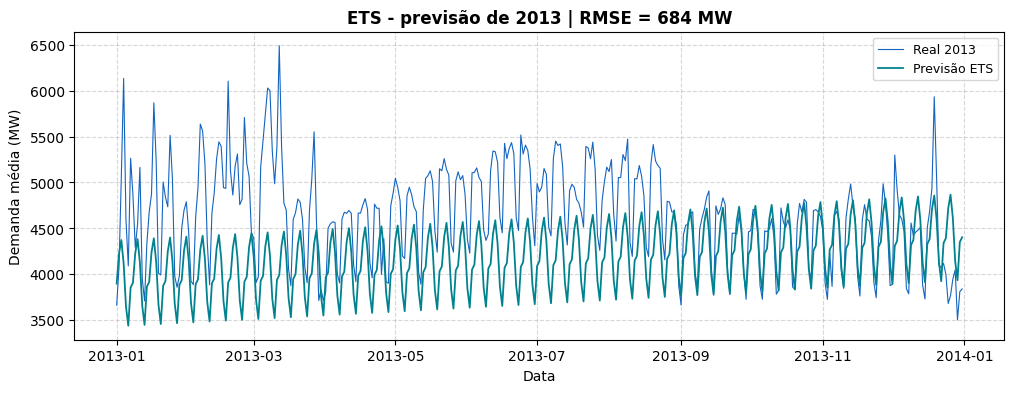

In [51]:
plot_previsao('ETS', cv_valid.index, cv_valid.values, prev_validacao['ETS'], rmse_val['ETS'], '2013', COR_SERIE)

- **Validação 2013: LSTM**

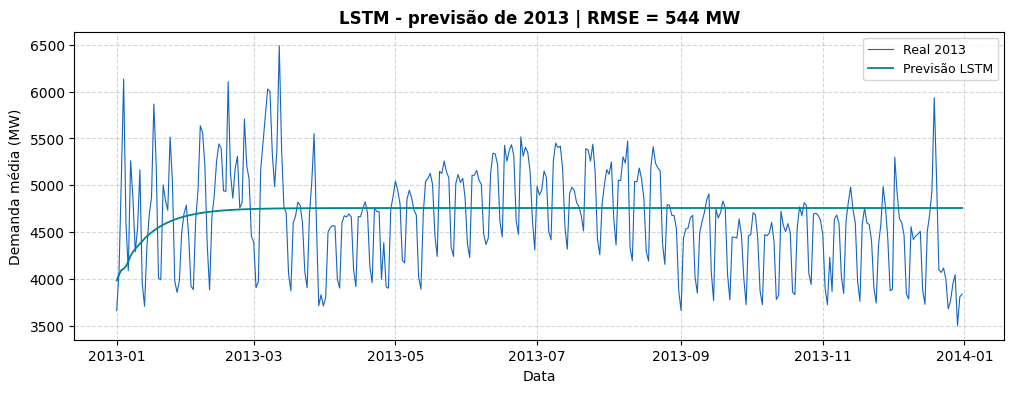

In [52]:
plot_previsao('LSTM', cv_valid.index, cv_valid.values, prev_validacao['LSTM'], rmse_val['LSTM'], '2013', COR_SERIE)

- **Validação 2013: ARIMA**

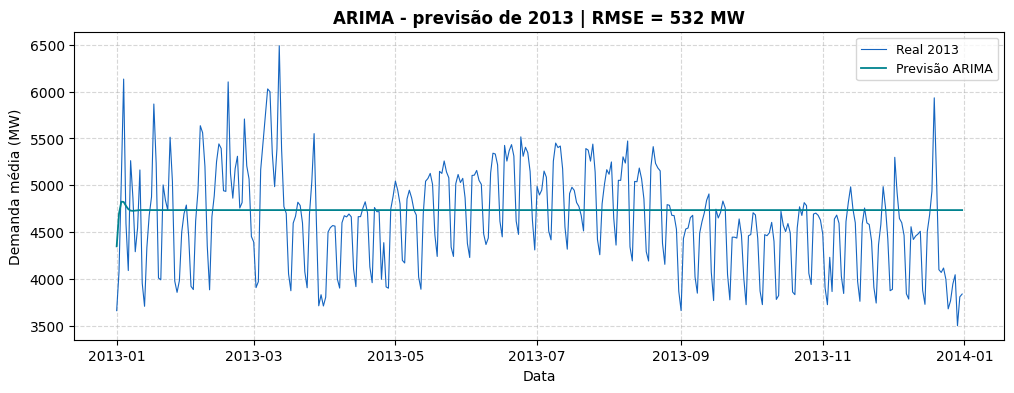

In [53]:
plot_previsao('ARIMA', cv_valid.index, cv_valid.values, prev_validacao['ARIMA'], rmse_val['ARIMA'], '2013', COR_SERIE)

- **Validação 2013: Árvore**

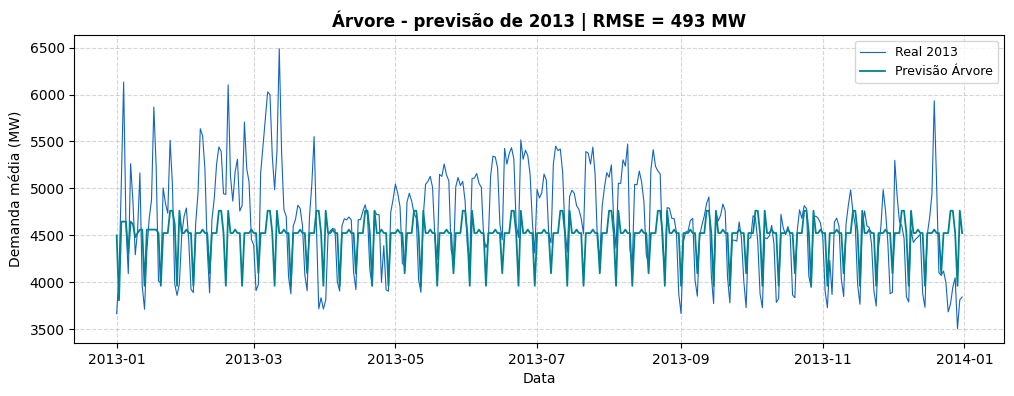

In [54]:
plot_previsao('Árvore', cv_valid.index, cv_valid.values, prev_validacao['Árvore'], rmse_val['Árvore'], '2013', COR_SERIE)

### <font color = Blue> **Os dois que deram mais certo: SARIMA e Prophet**

Os únicos que ficaram abaixo do sazonal ingênuo na validação.

- **Validação 2013: SARIMA**

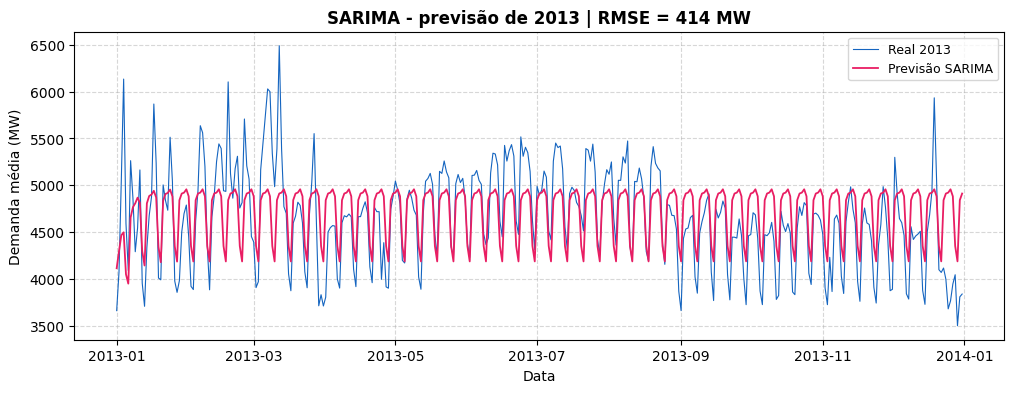

In [55]:
plot_previsao('SARIMA', cv_valid.index, cv_valid.values, prev_validacao['SARIMA'], rmse_val['SARIMA'], '2013', COR_SERIE)

- **Validação 2013: Prophet**

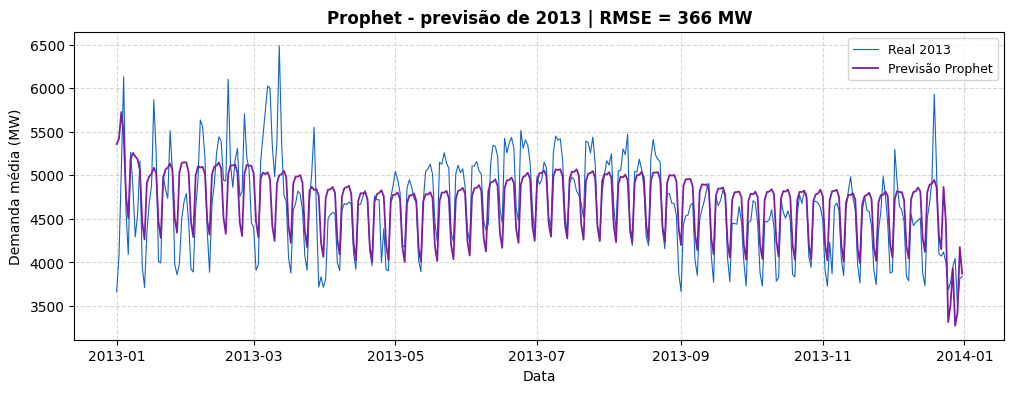

In [56]:
plot_previsao('Prophet', cv_valid.index, cv_valid.values, prev_validacao['Prophet'], rmse_val['Prophet'], '2013', COR_SERIE)

- **O que aconteceu com cada modelo na validação (previsão de 2013)**

  - **Referências:** repetir o ano anterior (sazonal ingênuo) dá **455 MW** e prever sempre a média dá **535 MW**. Só o **Prophet** e o **SARIMA** ficaram abaixo do sazonal ingênuo.

  - **O que deu errado:**
    - **ETS (684 MW):** a melhor configuração tem tendência **multiplicativa**. Como a origem (31/12/2012) está no vale das festas, o modelo começa baixo e projeta uma subida o ano inteiro.
    - **LSTM (544 MW):** na previsão recursiva o padrão semanal **some** em poucas semanas e a previsão vira um valor constante, pior que prever a média. Com a diferença de 7 dias ficou acima de 1.200 MW, porque o erro de cada passo se acumula quando a diferença é desfeita.
    - **ARIMA (532 MW):** sem sazonalidade, vira uma **linha reta na média** depois de poucos dias. O erro é praticamente o de prever a média (535 MW).
    - **Árvore (493 MW):** na previsão recursiva o padrão semanal fica **achatado**, preso numa faixa estreita, porque a árvore só prevê valores que viu no treino.

  - **Os dois que deram mais certo:**
    - **Prophet (366 MW):** aditivo, tendência rígida (`cps = 0.001`), festas como datas especiais e o **|z| da temperatura do ano anterior suavizado em 30 dias**. É o único cuja previsão **sobe e desce com as estações** e prevê o vale das festas.
    - **SARIMA (414 MW):** aprende o perfil médio da semana e repete esse perfil o ano todo, sem variação entre as estações.

- **O que a temperatura acrescentou ao Prophet** (tabela da 4.5)

  - **|z|:**
    - sem regressor, o melhor Prophet teve **420 MW**;
    - com o |z| **diário** do ano anterior piorou (**431 MW**), porque a temperatura de um dia de 2012 não diz nada sobre o mesmo dia de 2013;
    - suavizando, o erro cai: **389 MW** (7 dias), **372 MW** (14 dias) e **366 MW** (30 dias).
  - **Frio + calor** (dois regressores) não melhorou a validação: **448 MW** (diário), **416 MW** (7 dias), **410 MW** (14 dias) e **426 MW** (30 dias). Uma explicação provável: com 1 ano de treino há um único inverno e um único verão para estimar dois coeficientes. Isso é pouco dado para mais parâmetros.
  - Os RMSE do Prophet podem mudar alguns MW em outra máquina (por exemplo, no Colab), por causa da otimização interna do Prophet.

In [57]:
melhor = comparacao.iloc[0]
familia_escolhida = melhor['Família']
funcao_escolhida, linha_escolhida = melhores[familia_escolhida]
config_escolhida = linha_escolhida['config']

segunda = comparacao.iloc[1]
familia_segunda = segunda['Família']
config_segunda = melhores[familia_segunda][1]['config']

COR_FAMILIA = {'SARIMA': COR_SARIMA, 'Prophet': COR_PROPHET}
cor_escolhida = COR_FAMILIA.get(familia_escolhida, COR_ALERTA)
cor_segunda = COR_FAMILIA.get(familia_segunda, COR_ALERTA)


def prever_com_intervalo(familia, config, serie, n):
    # Previsao + intervalo de 95% no mesmo formato (mean, lower, upper) para Prophet e SARIMA
    datas = pd.date_range(serie.index[-1] + pd.Timedelta(days=1), periods=n, freq='D')
    if familia == 'Prophet':
        modelo, prev = prever_prophet(serie, config, n, retornar_modelo=True)
        tabela = pd.DataFrame({'mean': prev['yhat'].values, 'lower': prev['yhat_lower'].values,
                               'upper': prev['yhat_upper'].values, 'trend': prev['trend'].values}, index=datas)
    else:
        ordem, ordem_sazonal = config
        modelo = ARIMA(serie, order=ordem, seasonal_order=ordem_sazonal).fit()
        f = modelo.get_forecast(steps=n).summary_frame(alpha=0.05)
        tabela = pd.DataFrame({'mean': f['mean'].values, 'lower': f['mean_ci_lower'].values,
                               'upper': f['mean_ci_upper'].values}, index=datas)
    return modelo, tabela


def historico_original(modelo):
    # O Prophet guarda o regressor do histórico já padronizado (média 0, desvio 1).
    # Aqui ele volta para a escala original, para o predict não padronizar duas vezes.
    hist = modelo.history[['ds'] + list(modelo.extra_regressors)].copy()
    for nome, info in modelo.extra_regressors.items():
        hist[nome] = hist[nome] * info['std'] + info['mu']
    return hist


def residuo_ajuste(familia, modelo):
    # Residuo dentro do periodo ajustado (real - ajustado)
    if familia == 'Prophet':
        ajuste = modelo.predict(historico_original(modelo))
        return pd.Series(modelo.history['y'].values - ajuste['yhat'].values, index=pd.DatetimeIndex(modelo.history['ds']))
    return modelo.resid.iloc[7:]  # descarta a primeira semana (inicio do ajuste)


print("Modelo escolhido:", melhor['Modelo'])
print("RMSE na validação:", round(melhor['RMSE validação'], 1), "MW")
print("Segundo colocado:", segunda['Modelo'], "->", round(segunda['RMSE validação'], 1), "MW")

Modelo escolhido: Prophet (additive, cps=0.001, com festas, |z| MM30)
RMSE na validação: 366.5 MW
Segundo colocado: SARIMA(1,0,0)(1,0,1)[7] -> 414.2 MW


### <font color = Blue> **4.8 - Prophet x SARIMA: por que o Prophet?**

A diferença no RMSE da validação é de **48 MW** (366 x 414 MW). Vale olhar **onde** cada um acerta e erra, ainda só com a validação (2013).

In [58]:
# Festas (24/12 a 02/01) x resto do ano na validacao
datas = cv_valid.index
mascara_festas = ((datas.month == 12) & (datas.day >= 24)) | ((datas.month == 1) & (datas.day <= 2))

prev_s = prev_validacao['SARIMA']
prev_p = prev_validacao['Prophet']

tabela_festas = pd.DataFrame({
    'Período': [f'Festas ({mascara_festas.sum()} dias)', f'Resto do ano ({(~mascara_festas).sum()} dias)', 'Ano todo'],
    'SARIMA': [root_mean_squared_error(cv_valid[mascara_festas], prev_s[mascara_festas]),
               root_mean_squared_error(cv_valid[~mascara_festas], prev_s[~mascara_festas]),
               root_mean_squared_error(cv_valid, prev_s)],
    'Prophet': [root_mean_squared_error(cv_valid[mascara_festas], prev_p[mascara_festas]),
                root_mean_squared_error(cv_valid[~mascara_festas], prev_p[~mascara_festas]),
                root_mean_squared_error(cv_valid, prev_p)]
}).round(0)
tabela_festas

,Período,SARIMA,Prophet
0,Festas (10 dias),877.0,764.0
1,Resto do ano (355 dias),393.0,349.0
2,Ano todo,414.0,366.0


In [59]:
# Em quantos dias de 2013 o Prophet errou menos que o SARIMA?
prophet_melhor = np.abs(cv_valid.values - prev_p) < np.abs(cv_valid.values - prev_s)
print("Dias em que o Prophet errou menos que o SARIMA:", prophet_melhor.sum(), "de", len(prophet_melhor),
      f"({prophet_melhor.mean() * 100:.0f}%)")
print("Só fora das festas:", prophet_melhor[~mascara_festas].sum(), "de", (~mascara_festas).sum(),
      f"({prophet_melhor[~mascara_festas].mean() * 100:.0f}%)")

Dias em que o Prophet errou menos que o SARIMA: 245 de 365 (67%)
Só fora das festas: 238 de 355 (67%)


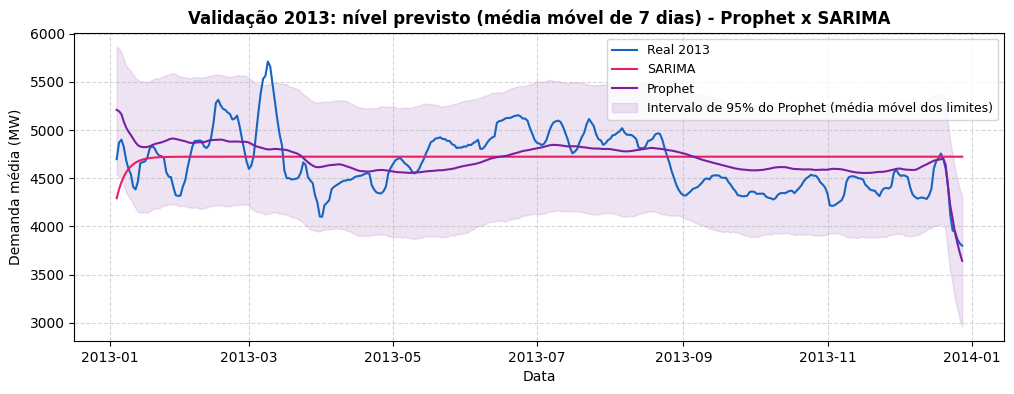

In [60]:
# Nivel previsto (media movel de 7 dias para tirar o padrao semanal)
comp_prophet = prever_prophet(cv_treino, melhores['Prophet'][1]['config'], h, intervalo=True)

plt.figure(figsize=(12, 4))
plt.plot(cv_valid.index, cv_valid.rolling(7, center=True).mean(), color=COR_SERIE, linewidth=1.5, label='Real 2013')
plt.plot(cv_valid.index, pd.Series(prev_s).rolling(7, center=True).mean(), color=COR_SARIMA, linewidth=1.5, label='SARIMA')
plt.plot(cv_valid.index, pd.Series(prev_p).rolling(7, center=True).mean(), color=COR_PROPHET, linewidth=1.5, label='Prophet')
plt.fill_between(cv_valid.index, comp_prophet['yhat_lower'].rolling(7, center=True).mean(),
                 comp_prophet['yhat_upper'].rolling(7, center=True).mean(), color=COR_PROPHET, alpha=0.12,
                 label='Intervalo de 95% do Prophet (média móvel dos limites)')
plt.title('Validação 2013: nível previsto (média móvel de 7 dias) - Prophet x SARIMA', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9, loc='upper right')
plt.show()

- **Do que é feita a previsão do Prophet para 2013**

A previsão é a soma das partes abaixo: **tendência + semana + festas + temperatura**. Cada gráfico mostra uma parte.

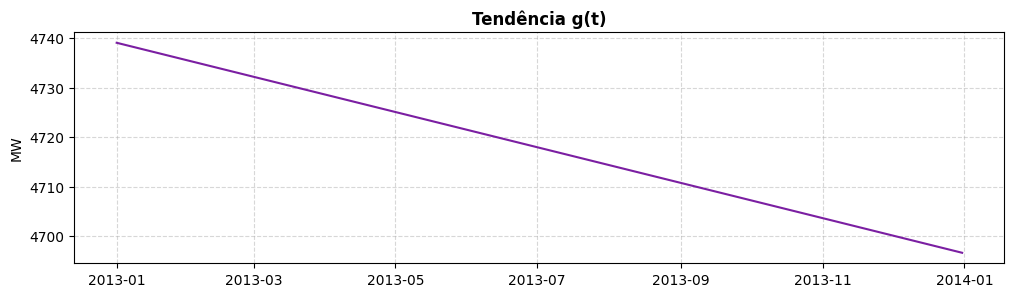

In [61]:
plt.figure(figsize=(12, 3))
plt.plot(cv_valid.index, comp_prophet['trend'].values, color=COR_PROPHET, linewidth=1.5)
plt.title('Tendência g(t)', fontweight='bold')
plt.ylabel('MW')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

Quase plana: a tendência não explica a variação ao longo do ano

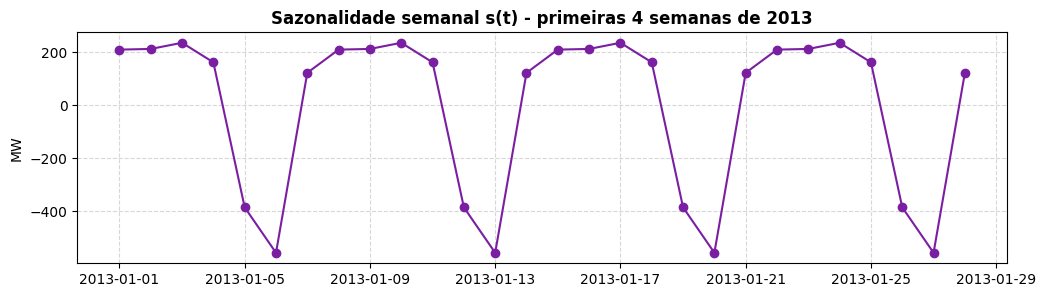

In [62]:
plt.figure(figsize=(12, 3))
plt.plot(cv_valid.index[:28], comp_prophet['weekly'].values[:28], color=COR_PROPHET, marker='o', linewidth=1.5)
plt.title('Sazonalidade semanal s(t) - primeiras 4 semanas de 2013', fontweight='bold')
plt.ylabel('MW')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

Mesmo padrão toda semana: sobe nos dias úteis e cai no sábado e domingo

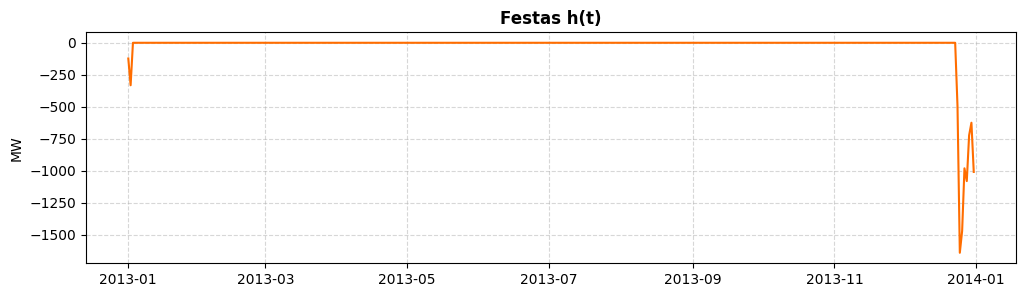

In [63]:
plt.figure(figsize=(12, 3))
plt.plot(cv_valid.index, comp_prophet['holidays'].values, color=COR_DESTAQUE, linewidth=1.5)
plt.title('Festas h(t)', fontweight='bold')
plt.ylabel('MW')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

Só atua de 24/12 a 02/01

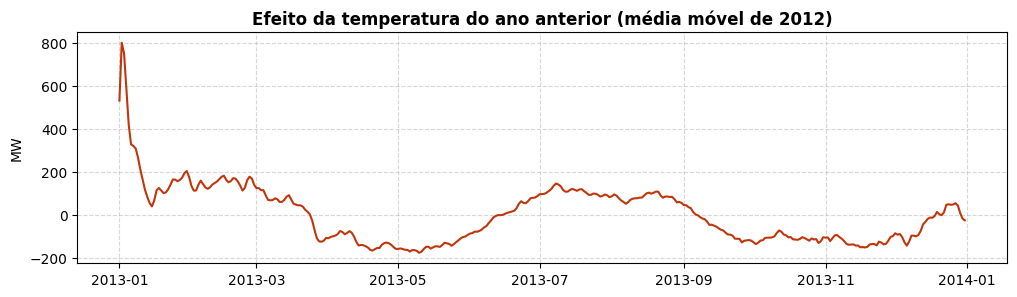

In [64]:
# Efeito da temperatura: soma dos regressores usados (|z| ou frio + calor)
nomes_temp = [n for n in ['abs_z_temp', 'z_frio', 'z_calor'] if n in comp_prophet.columns]
efeito = comp_prophet[nomes_temp].sum(axis=1)

plt.figure(figsize=(12, 3))
plt.plot(cv_valid.index, efeito.values, color=COR_TEMP, linewidth=1.5)
plt.title('Efeito da temperatura do ano anterior (média móvel de 2012)', fontweight='bold')
plt.ylabel('MW')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

É esta parte que faz a previsão subir no verão e no inverno

- **Escolha: Prophet**

  - **Menor RMSE na validação** (366 x 414 MW), que é o critério do enunciado. A diferença é de 48 MW (12%).
  - **Ganha nas festas e no resto do ano:** nas festas (10 dias) erra 764 x 877 MW do SARIMA. Nos outros **355 dias** também erra menos: **349 x 393 MW**.
  - **Ganha no dia a dia:** foi melhor que o SARIMA em **245 de 365 dias** (67%) de 2013.
  - **A média móvel não é uma linha reta.** No gráfico do nível (média móvel de 7 dias), a previsão do Prophet **sobe e desce com as estações**: sobe no verão e no inverno, desce no outono e na primavera e cai nas festas, como a série real. A do SARIMA é **uma linha reta**: repete o mesmo perfil semanal o ano todo e não mostra quando a demanda sobe. Para planejar energia, saber **em que época** a demanda aumenta é tão importante quanto o erro médio.
  - **Quem faz a curva é a temperatura, não a tendência:** nos componentes, a tendência g(t) é quase plana. A variação ao longo do ano vem do efeito da temperatura do ano anterior.
  - **Sem olhar o futuro:** na previsão, o regressor usa só temperaturas do ano anterior, com média móvel só para trás e base fixa em 2012.

- **Pontos fracos já visíveis na validação**

  - **Ondas de calor pontuais** (ex.: março de 2013) não são previstas: o regressor mostra a estação, não o dia quente.
  - **Início de janeiro:** a previsão começa acima do real. Para os primeiros dias de 2013, o regressor vem do começo de 2012, onde a média móvel de 30 dias ainda tem poucos dias (é o início da série), e sai alto.
  - **Validação otimista:** é uma única janela (2012 → 2013) e a grade do Prophet tem 144 configurações. A melhor de muitas numa única janela tende a parecer melhor do que é. O teste (Parte 5) mede isso, sem mudar a escolha.

**A partir daqui (Partes 5 e 6), só o Prophet é avaliado.** O SARIMA volta apenas em um gráfico no fim da Parte 6, para ilustrar a escolha (sem nova avaliação).

## <font color = Blue> **Parte 5 - Avaliação do modelo no conjunto de teste**

- **Treine o modelo escolhido em todo o conjunto de treino**;
- **Avalie o modelo (escolhido na Parte 4) no conjunto de teste**. Para isso:
  - Faça a predição dos **`h` dias**, sem utilizar valores reais do teste para atualizar as previsões, e compare com os dados observados;
  - Inclua **intervalo de previsão de 95% quando o modelo oferecer esse recurso**; caso contrário, justifique sua ausência;
  - Calcule o **RMSE no conjunto de teste, na escala original**;
- Não utilize o resultado do teste para trocar ou reajustar a configuração do modelo escolhido.

- **Modelo escolhido treinado com 2012 + 2013 e previsão de 2014 com intervalo de 95%**

In [65]:
modelo_teste, prev_teste = prever_com_intervalo(familia_escolhida, config_escolhida, y_treino, h)

rmse_teste = root_mean_squared_error(y_teste, prev_teste['mean'])
dentro = (y_teste >= prev_teste['lower']) & (y_teste <= prev_teste['upper'])

print("Modelo:", melhor['Modelo'])
print("RMSE no teste =", round(rmse_teste, 1), "MW,", round(rmse_teste / y_teste.mean() * 100, 1), "% da demanda média de 2014")
print("Dias de 2014 dentro do intervalo de 95%:", round(dentro.mean() * 100, 1), "%")
print("Média prevista para 2014:", round(prev_teste['mean'].mean()), "MW | real:", round(y_teste.mean()), "MW")

Modelo: Prophet (additive, cps=0.001, com festas, |z| MM30)
RMSE no teste = 493.5 MW, 10.7 % da demanda média de 2014
Dias de 2014 dentro do intervalo de 95%: 92.6 %
Média prevista para 2014: 4395 MW | real: 4610 MW


- **Teste 2014: série completa (treino + teste + previsão)**

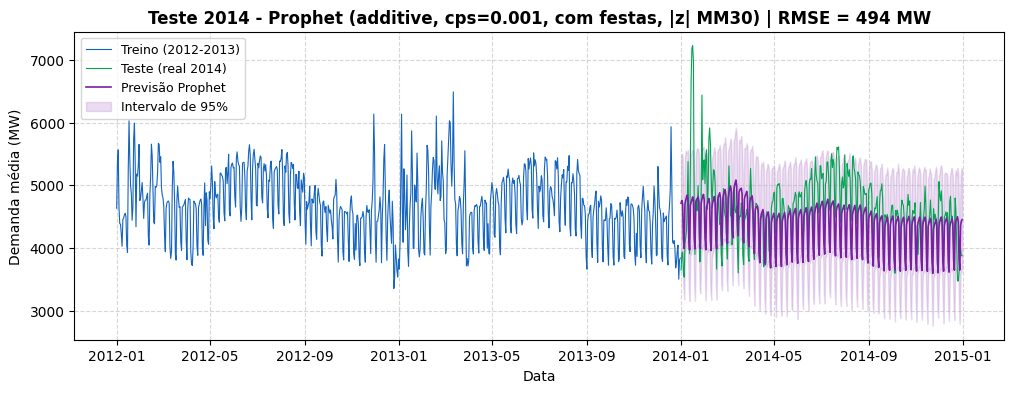

In [66]:
plt.figure(figsize=(12, 4))
plt.plot(y_treino, color=COR_SERIE, linewidth=0.8, label='Treino (2012-2013)')
plt.plot(y_teste, color=COR_TESTE, linewidth=0.8, label='Teste (real 2014)')
plt.plot(prev_teste['mean'], color=cor_escolhida, linewidth=1.2, label=f'Previsão {familia_escolhida}')
plt.fill_between(prev_teste.index, prev_teste['lower'], prev_teste['upper'], color=cor_escolhida, alpha=0.15, label='Intervalo de 95%')
plt.title(f"Teste 2014 - {melhor['Modelo']} | RMSE = {rmse_teste:.0f} MW", fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=9)
plt.show()

- **Teste 2014: dia a dia**

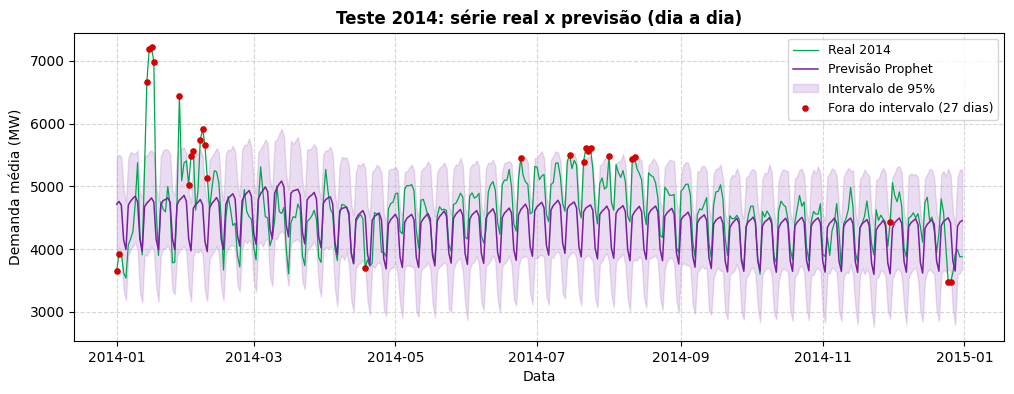

In [67]:
fora = ~dentro

plt.figure(figsize=(12, 4))
plt.plot(y_teste, color=COR_TESTE, linewidth=0.9, label='Real 2014')
plt.plot(prev_teste['mean'], color=cor_escolhida, linewidth=1.1, label=f'Previsão {familia_escolhida}')
plt.fill_between(prev_teste.index, prev_teste['lower'], prev_teste['upper'], color=cor_escolhida, alpha=0.15, label='Intervalo de 95%')
plt.scatter(y_teste.index[fora], y_teste[fora], color=COR_ALERTA, s=14, zorder=3, label=f'Fora do intervalo ({fora.sum()} dias)')
plt.title('Teste 2014: série real x previsão (dia a dia)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=9)
plt.show()

- **Teste 2014: nível (média móvel de 7 dias) com intervalo de 95%**

A média móvel de 7 dias tira o padrão semanal e deixa só o **nível** ao longo do ano. A faixa é a média móvel de 7 dias dos limites diários do intervalo de 95%. É uma aproximação visual: o intervalo exato de uma média de 7 dias seria um pouco mais estreito.

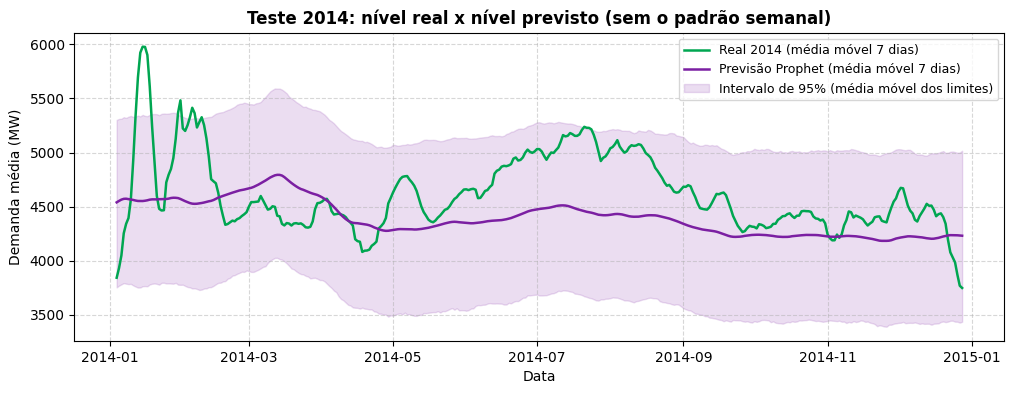

In [68]:
plt.figure(figsize=(12, 4))
plt.plot(y_teste.rolling(7, center=True).mean(), color=COR_TESTE, linewidth=1.8, label='Real 2014 (média móvel 7 dias)')
plt.plot(prev_teste['mean'].rolling(7, center=True).mean(), color=cor_escolhida, linewidth=1.8, label=f'Previsão {familia_escolhida} (média móvel 7 dias)')
plt.fill_between(prev_teste.index, prev_teste['lower'].rolling(7, center=True).mean(), prev_teste['upper'].rolling(7, center=True).mean(),
                 color=cor_escolhida, alpha=0.15, label='Intervalo de 95% (média móvel dos limites)')
plt.title('Teste 2014: nível real x nível previsto (sem o padrão semanal)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=9)
plt.show()

- **Teste 2014: real x previsto** (quanto mais perto da linha tracejada, melhor)

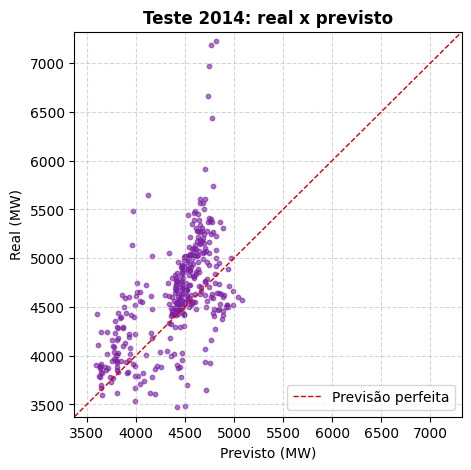

In [69]:
plt.figure(figsize=(5, 5))
plt.scatter(prev_teste['mean'], y_teste, s=10, color=cor_escolhida, alpha=0.6)
lim = [min(y_teste.min(), prev_teste['mean'].min()) - 100, max(y_teste.max(), prev_teste['mean'].max()) + 100]
plt.plot(lim, lim, color=COR_ALERTA, linestyle='--', linewidth=1, label='Previsão perfeita')
plt.xlim(lim)
plt.ylim(lim)
plt.title('Teste 2014: real x previsto', fontweight='bold')
plt.xlabel('Previsto (MW)')
plt.ylabel('Real (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

- **Teste 2014: visão geral com as estações do ano** (média móvel de 7 dias)

As bolinhas no topo marcam as estações do hemisfério sul (Melbourne): verão (dez-fev), outono (mar-mai), inverno (jun-ago) e primavera (set-nov). A linha pontilhada preta marca o início do teste.

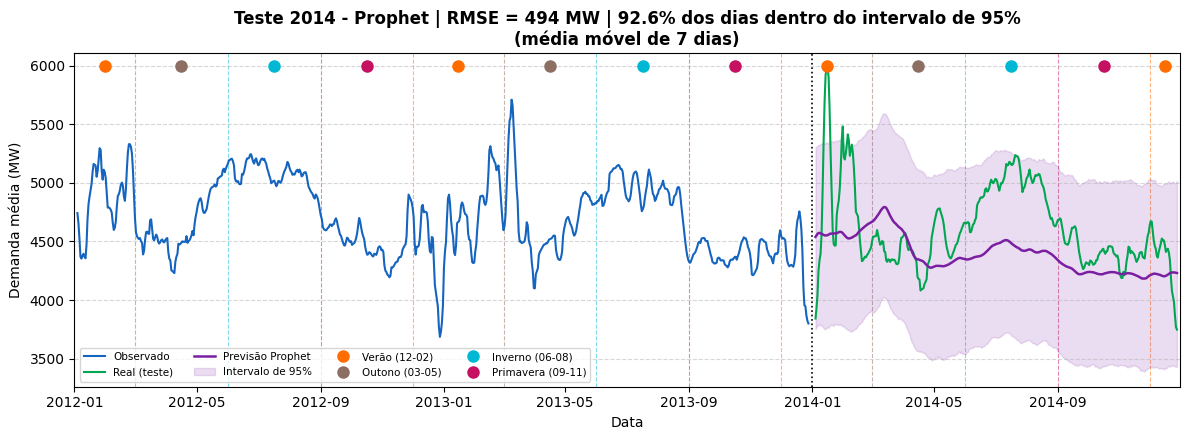

In [70]:
# Estações do hemisfério sul: nome, mês de início e cor da bolinha
ESTACOES = [('Verão', 12, '#FF6D00'),
            ('Outono', 3, '#8D6E63'),
            ('Inverno', 6, '#00B8D4'),
            ('Primavera', 9, '#C51162')]


def media_movel_7(s):
    return s.rolling(7, center=True).mean()


def marcar_estacoes(a, inicio, fim):
    # bolinha no meio de cada estação + linha tracejada na troca de estação
    for nome, mes, cor_est in ESTACOES:
        for ano in range(inicio.year - 1, fim.year + 1):
            ini = pd.Timestamp(ano, mes, 1)
            fim_est = ini + pd.DateOffset(months=3)
            if fim_est <= inicio or ini >= fim:
                continue
            if ini > inicio:
                a.axvline(ini, color=cor_est, linestyle='--', linewidth=0.8, alpha=0.5, zorder=0)
            meio = max(ini, inicio) + (min(fim_est, fim) - max(ini, inicio)) / 2
            a.plot(meio, 0.96, 'o', color=cor_est, markersize=8, transform=a.get_xaxis_transform(), clip_on=False)
    legenda = []
    for nome, mes, cor_est in ESTACOES:
        legenda.append(Line2D([], [], marker='o', linestyle='', color=cor_est, markersize=8, label=f'{nome} ({mes:02d}-{(mes + 1) % 12 + 1:02d})'))
    return legenda


def grafico_estacoes(observado, prev, titulo, real=None):
    # Série observada + previsão + intervalo de 95%, tudo em média móvel de 7 dias, com as estações marcadas
    inicio, fim = observado.index[0], prev.index[-1]
    fig, a = plt.subplots(figsize=(12, 4.5))
    a.plot(media_movel_7(observado), color=COR_SERIE, linewidth=1.5, label='Observado')
    if real is not None:
        a.plot(media_movel_7(real), color=COR_TESTE, linewidth=1.5, label='Real (teste)')
    a.plot(media_movel_7(prev['mean']), color=COR_PROPHET, linewidth=1.8, label='Previsão Prophet')
    a.fill_between(prev.index, media_movel_7(prev['lower']), media_movel_7(prev['upper']), color=COR_PROPHET, alpha=0.15, label='Intervalo de 95%')
    a.axvline(prev.index[0], color='black', linestyle=':', linewidth=1.2)
    legenda_estacoes = marcar_estacoes(a, inicio, fim)
    a.set_xlim(inicio, fim)
    a.set_title(titulo, fontweight='bold')
    a.set_xlabel('Data')
    a.set_ylabel('Demanda média (MW)')
    a.grid(axis='y', linestyle='--', alpha=0.5)
    handles, labels = a.get_legend_handles_labels()
    a.legend(handles + legenda_estacoes, labels + [l.get_label() for l in legenda_estacoes], loc='lower left', fontsize=7.5, ncol=4)
    plt.tight_layout()
    plt.show()


grafico_estacoes(y_treino, prev_teste, f'Teste 2014 - Prophet | RMSE = {rmse_teste:.0f} MW | {dentro.mean() * 100:.1f}% dos dias dentro do intervalo de 95%\n(média móvel de 7 dias)', real=y_teste)

- **Componentes do modelo treinado com 2012 + 2013** (gráfico padrão do Prophet, como na Aula 15)

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,abs_z_temp,additive,0.84,362.98,362.98,362.98


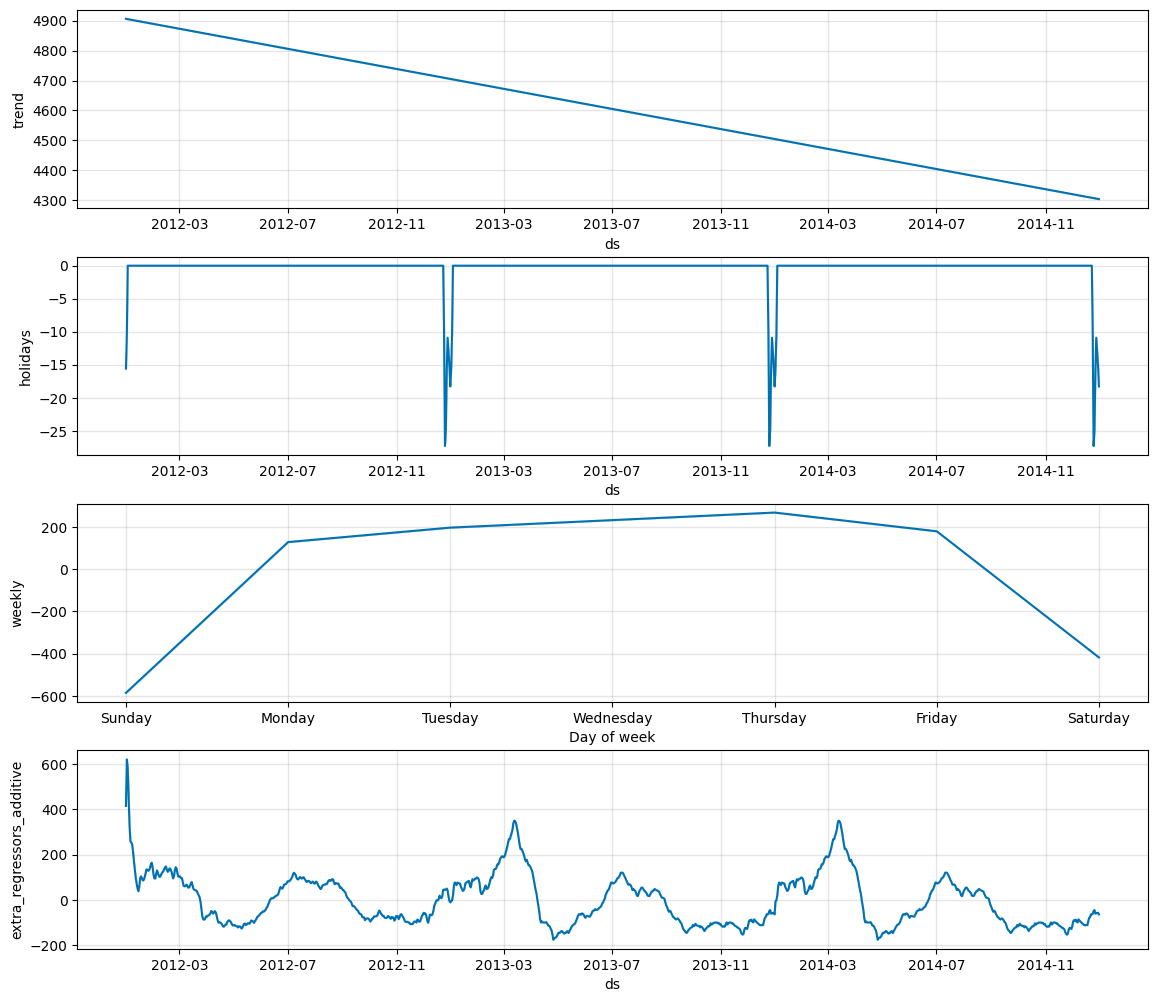

In [71]:
if familia_escolhida == 'Prophet':
    from prophet.utilities import regressor_coefficients
    if modelo_teste.extra_regressors:
        display(regressor_coefficients(modelo_teste).round(2))
    # historico + 2014 (com o regressor do ano anterior no periodo previsto)
    hist = historico_original(modelo_teste)  # regressor na escala original
    fut = regressores_futuro(prev_teste.index, config_escolhida).rename_axis('ds').reset_index()
    fig = modelo_teste.plot_components(modelo_teste.predict(pd.concat([hist, fut], ignore_index=True)))
    fig.set_size_inches(12, 2.5 * len(fig.axes))
    plt.show()
else:
    display(modelo_teste.params.round(3))

- **Análise dos resíduos** (ajuste em 2012 + 2013)

Se o modelo capturou toda a estrutura da série, o resíduo deve se parecer com um **ruído branco**: média perto de zero, sem padrão no tempo e sem autocorrelação. O **teste de Ljung-Box** verifica isso.
  - **Hipótese nula do Ljung-Box**: `Não há autocorrelação nos resíduos até o lag testado`
  - p-value pequeno (≤ 0,05) indica que **ainda sobra estrutura** que o modelo não capturou.

Média do resíduo: -11.7 MW | desvio-padrão: 378.9 MW


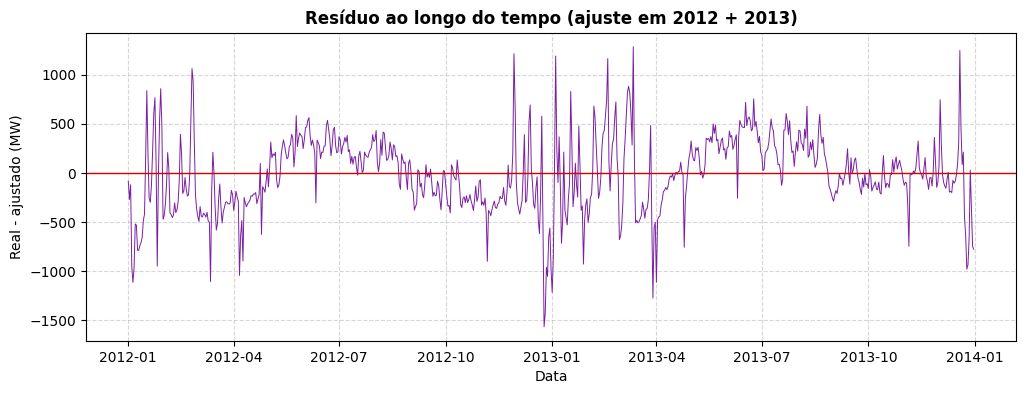

In [72]:
residuo = residuo_ajuste(familia_escolhida, modelo_teste)
print("Média do resíduo:", round(residuo.mean(), 1), "MW | desvio-padrão:", round(residuo.std(), 1), "MW")

plt.figure(figsize=(12, 4))
plt.plot(residuo, color=cor_escolhida, linewidth=0.7)
plt.axhline(0, color=COR_ALERTA, linewidth=1)
plt.title('Resíduo ao longo do tempo (ajuste em 2012 + 2013)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Real - ajustado (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

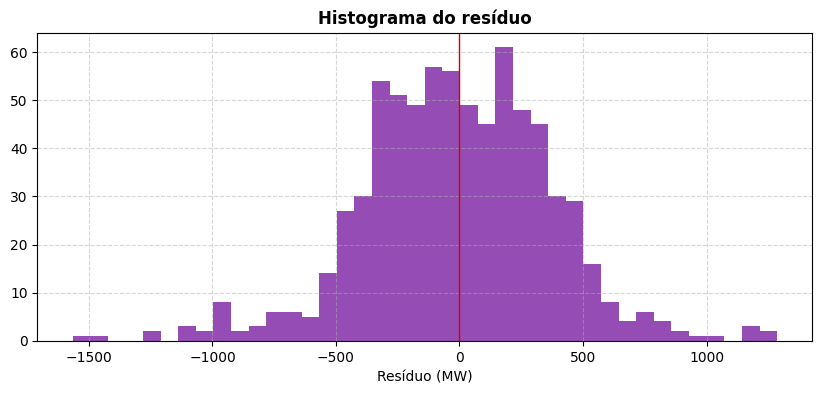

In [73]:
plt.figure(figsize=(10, 4))
plt.hist(residuo, bins=40, color=cor_escolhida, alpha=0.8)
plt.axvline(0, color=COR_ALERTA, linewidth=1)
plt.title('Histograma do resíduo', fontweight='bold')
plt.xlabel('Resíduo (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

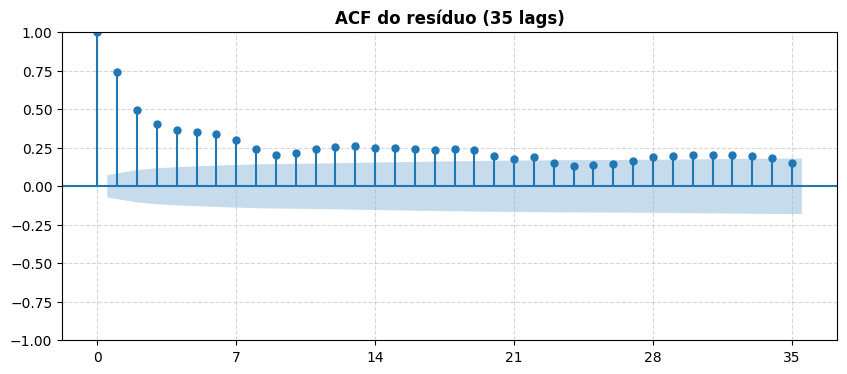

In [74]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(residuo, lags=35, ax=ax)
plt.xticks(range(0, 36, 7))
plt.title('ACF do resíduo (35 lags)', fontweight='bold')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

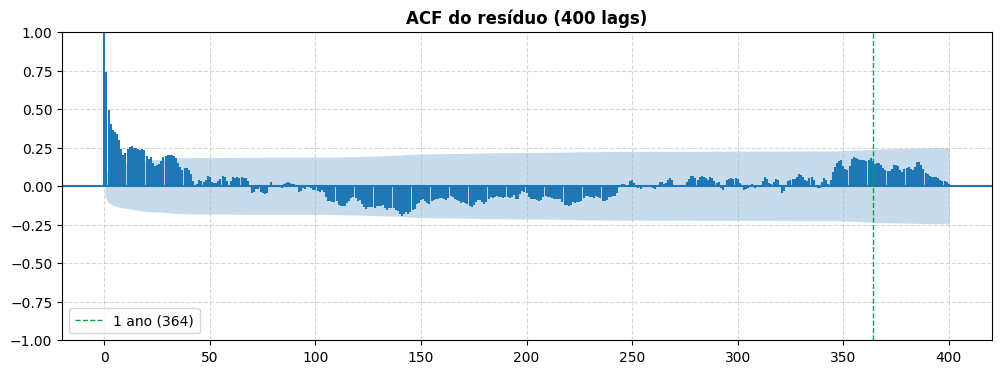

In [75]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(residuo, lags=400, ax=ax, marker='')
plt.axvline(364, color=COR_TESTE, linestyle='--', linewidth=1, label='1 ano (364)')
plt.title('ACF do resíduo (400 lags)', fontweight='bold')
plt.grid(linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [76]:
# Teste de Ljung-Box nos lags 7, 14, 28 e 364
acorr_ljungbox(residuo, lags=[7, 14, 28, 364])

,lb_stat,lb_pvalue
7,1049.495574,2.428299e-222
14,1348.352492,2.128929e-279
28,1754.054605,0.000000e+00
364,4336.897317,0.000000e+00


- **Leitura dos resíduos**

  - **Média de -12 MW**, praticamente zero: dentro do período ajustado, o modelo não erra sistematicamente para cima nem para baixo. O desvio-padrão é de 379 MW.
  - **Cuidado no cálculo:** o Prophet guarda o regressor do histórico já padronizado. A função `historico_original` volta o regressor para a escala original antes do `predict`. Sem ela, o regressor seria padronizado duas vezes e a média do resíduo sairia errada (cerca de 290 MW).
  - **O Ljung-Box rejeita o ruído branco em todos os lags testados** (7, 14, 28 e 364; p ≈ 0). Ainda sobra estrutura:
    - **Lags curtos:** dias seguidos erram juntos, como nas ondas de calor, que o modelo não prevê.
    - **Lag 364:** parte do ciclo das estações não foi capturada, porque o modelo só o vê pela temperatura suavizada do ano anterior.

- **Prophet x referências simples no teste**

As referências não são modelos: servem de régua. Mostram quanto o Prophet ganha em relação a prever a média e a repetir o ano anterior.

                 RMSE no teste (MW)
Prophet                       493.5
Sazonal ingênuo               487.0
Média                         559.5


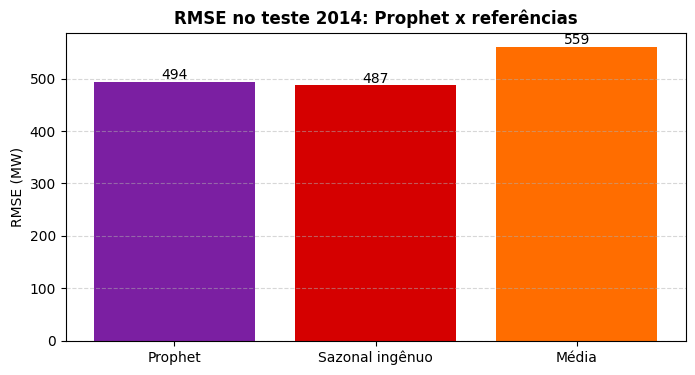

In [77]:
ref_teste = {}
for nome, funcao in referencias.items():
    ref_teste[nome] = calcular_rmse(y_teste, funcao(y_treino, None, h))

regua = pd.Series({'Prophet': rmse_teste, 'Sazonal ingênuo': ref_teste['Sazonal ingênuo'], 'Média': ref_teste['Média']})
print(regua.round(1).to_frame('RMSE no teste (MW)'))

plt.figure(figsize=(8, 4))
barras = plt.bar(regua.index, regua.values, color=[COR_PROPHET, COR_ALERTA, COR_DESTAQUE])
plt.bar_label(barras, fmt='%.0f')
plt.title('RMSE no teste 2014: Prophet x referências', fontweight='bold')
plt.ylabel('RMSE (MW)')
plt.grid(linestyle='--', alpha=0.5, axis='y')
plt.show()

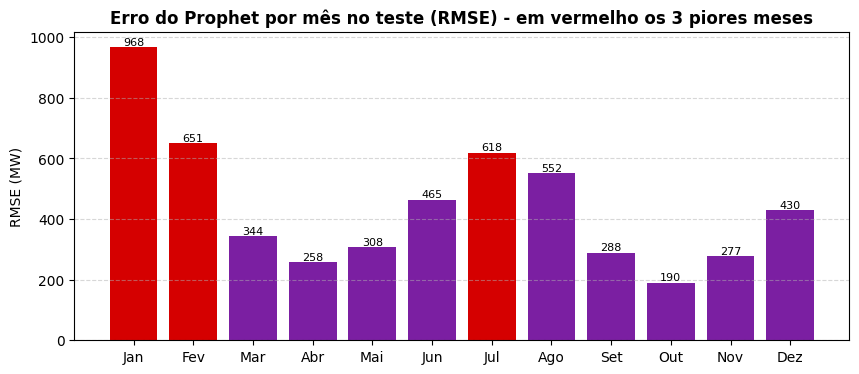

In [78]:
# Onde o modelo escolhido mais errou: RMSE por mes no teste
erro = y_teste - prev_teste['mean']
rmse_mes = erro.groupby(erro.index.month).apply(lambda e: np.sqrt((e**2).mean()))
rmse_mes.index = nomes_meses

piores = rmse_mes.nlargest(3).index  # os 3 meses com mais erro em destaque
cores_mes = [COR_ALERTA if m in piores else cor_escolhida for m in rmse_mes.index]

plt.figure(figsize=(10, 4))
barras = plt.bar(rmse_mes.index, rmse_mes.values, color=cores_mes)
plt.bar_label(barras, fmt='%.0f', fontsize=8)
plt.title(f"Erro do {familia_escolhida} por mês no teste (RMSE) - em vermelho os 3 piores meses", fontweight='bold')
plt.ylabel('RMSE (MW)')
plt.grid(linestyle='--', alpha=0.5, axis='y')
plt.show()

- **Diagnóstico: e se a temperatura fosse separada em frio e calor?**

**Só diagnóstico, a escolha não muda** (ela foi feita na validação, Parte 4). Usamos o modo, o `cps` e as festas do modelo escolhido e trocamos só o regressor de temperatura, para ver se separar frio e calor ajuda a acertar o **inverno**, onde o modelo escolhido mais subestima a demanda.

In [79]:
modo, cps, usar_festas = config_escolhida[:3]
versoes = {'Escolhido (|z| MM30)': config_escolhida,
           'Frio + calor MM7': (modo, cps, usar_festas, 7, 'frio_calor'),
           'Frio + calor MM30': (modo, cps, usar_festas, 30, 'frio_calor')}
inverno = (y_teste.index.month >= 6) & (y_teste.index.month <= 8)

prev_versoes = {}
linhas = []
for nome, cfg in versoes.items():
    modelo_v, p = prever_prophet(y_treino, cfg, h, retornar_modelo=True)
    p.index = y_teste.index
    prev_versoes[nome] = p
    erro_v = y_teste - p['yhat']
    linha = {'Versão': nome,
             'RMSE teste': np.sqrt((erro_v**2).mean()),
             'RMSE inverno (jun-ago)': np.sqrt((erro_v[inverno]**2).mean()),
             'RMSE resto do ano': np.sqrt((erro_v[~inverno]**2).mean()),
             'Média prevista no inverno': p['yhat'][inverno].mean()}
    coefs = regressor_coefficients(modelo_v).set_index('regressor')['coef']
    for r, v in coefs.items():
        linha[f'coef {r}'] = v
    linhas.append(linha)

tabela_versoes = pd.DataFrame(linhas).set_index('Versão')
print("Média real no inverno de 2014:", round(y_teste[inverno].mean()), "MW")
tabela_versoes.round(1)

Média real no inverno de 2014: 4930 MW


,RMSE teste,RMSE inverno (jun-ago),RMSE resto do ano,Média prevista no inverno,coef abs_z_temp,coef z_frio,coef z_calor
Versão,,,,,,,
Escolhido (|z| MM30),493.5,549.2,473.3,4417.1,363.0,NaN,NaN
Frio + calor MM7,492.9,392.4,522.4,4635.5,NaN,799.4,419.9
Frio + calor MM30,465.9,364.6,495.3,4610.2,NaN,730.8,333.6


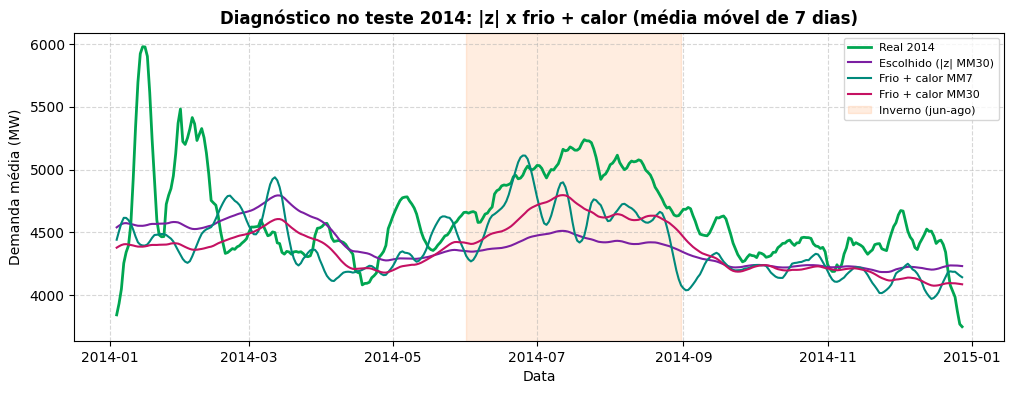

In [80]:
cores_versoes = [COR_PROPHET, '#00897B', '#C51162']

plt.figure(figsize=(12, 4))
plt.plot(y_teste.rolling(7, center=True).mean(), color=COR_TESTE, linewidth=2, label='Real 2014')
for (nome, p), cor in zip(prev_versoes.items(), cores_versoes):
    plt.plot(p['yhat'].rolling(7, center=True).mean(), color=cor, linewidth=1.5, label=nome)
plt.axvspan(pd.Timestamp('2014-06-01'), pd.Timestamp('2014-08-31'), color=COR_DESTAQUE, alpha=0.12, label='Inverno (jun-ago)')
plt.title('Diagnóstico no teste 2014: |z| x frio + calor (média móvel de 7 dias)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=8)
plt.show()

- **Análise do teste (2014)**

  - **RMSE de 494 MW**, 10,7% da demanda média de 2014.
  - **Intervalo de 95%:** cobriu **92,6%** dos dias, um pouco abaixo do esperado.
  - **Nível:** a média prevista foi de **4.395 MW**, contra **4.610 MW** reais (cerca de 215 MW abaixo).
  - **Comparação com as referências:**
    - **12% melhor que prever a média** (560 MW);
    - **praticamente empatado com repetir o ano anterior** (sazonal ingênuo, 487 MW).

    Na validação o Prophet tinha ficado 89 MW à frente do sazonal ingênuo. Essa vantagem não se repetiu, o que confirma que a validação de uma única janela foi otimista.
  - **Onde mais errou:**
    - **janeiro (968 MW) e fevereiro (651 MW):** a onda de calor de janeiro de 2014 levou a demanda acima de 7.000 MW;
    - **julho e agosto (618 e 552 MW):** o pico de inverno ficou cerca de 500 a 600 MW acima da previsão.

    Nos meses de transição (abril, setembro a novembro) o erro fica entre 190 e 290 MW.
  - **Formato (gráfico das estações):** a média móvel segue o formato do ano. Sobe no verão, desce no outono, sobe no inverno, cai na primavera e nas festas. Mas a **subida do inverno é pequena demais**.
  - **Diagnóstico frio + calor** (só diagnóstico, a escolha não muda):
    - Separando frio e calor, o erro do **inverno cai de 549 para 391 MW** (MM7) e **365 MW** (MM30). A média prevista no inverno sobe de 4.417 para cerca de 4.610 a 4.640 MW (real: 4.930 MW).
    - O coeficiente do frio é cerca de **2 vezes** o do calor (731 a 799 contra 333 a 420).
    - Isso indica que o efeito do inverno é maior que o do verão. Juntar os dois num único |z| subestima o inverno.

## <font color = Blue> **Parte 6 - Predição (forecast)**

- **Após concluir a avaliação, treine o modelo escolhido na série completa (treino + teste)**, mantendo a configuração selecionada;
- **Faça a predição para os próximos `h` dias**, incluindo plot e intervalo de previsão de 95% quando disponível; caso contrário, justifique sua ausência.

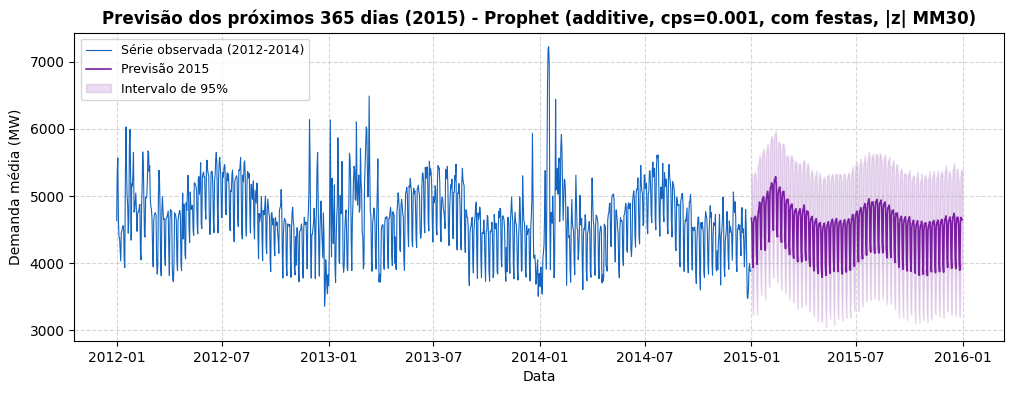

In [81]:
# Serie completa (2012 a 2014), mesma configuracao escolhida
y_completa = df.Demanda_Media_MW

modelo_final, prev_final = prever_com_intervalo(familia_escolhida, config_escolhida, y_completa, h)

plt.figure(figsize=(12, 4))
plt.plot(y_completa, color=COR_SERIE, linewidth=0.8, label='Série observada (2012-2014)')
plt.plot(prev_final['mean'], color=cor_escolhida, linewidth=1.2, label='Previsão 2015')
plt.fill_between(prev_final.index, prev_final['lower'], prev_final['upper'], color=cor_escolhida, alpha=0.15, label='Intervalo de 95%')
plt.title(f"Previsão dos próximos {h} dias (2015) - {melhor['Modelo']}", fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=9)
plt.show()

- **Previsão de 2015 sobre os anos observados (média móvel de 7 dias), com intervalo de 95%**

Os anos ficam no mesmo eixo (dia do ano) para comparar o formato. A faixa roxa é a média móvel de 7 dias dos limites do intervalo de 95%.

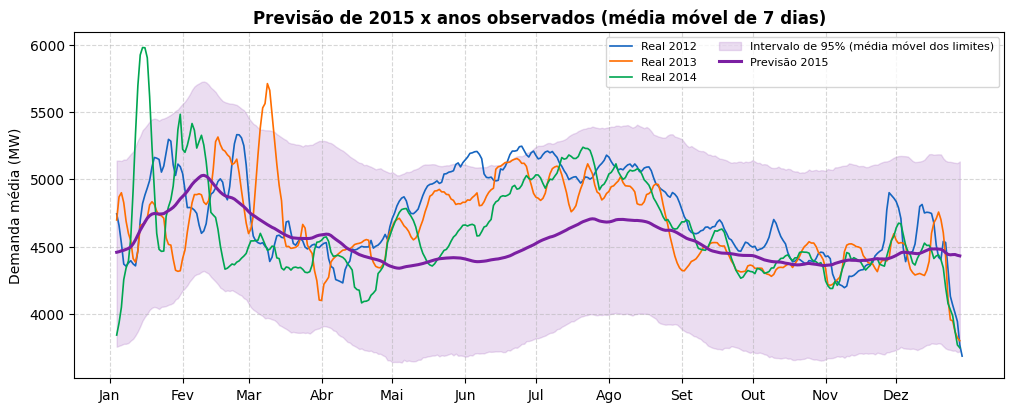

In [82]:
plt.figure(figsize=(12, 4.5))
for ano, cor in zip([2012, 2013, 2014], [COR_SERIE, COR_DESTAQUE, COR_TESTE]):
    s = y_completa.loc[str(ano)].rolling(7, center=True).mean()
    plt.plot(s.index.dayofyear, s.values, color=cor, linewidth=1.2, label=f'Real {ano}')

p = prev_final['mean'].rolling(7, center=True).mean()
inf = prev_final['lower'].rolling(7, center=True).mean()
sup = prev_final['upper'].rolling(7, center=True).mean()
plt.fill_between(p.index.dayofyear, inf.values, sup.values, color=cor_escolhida, alpha=0.15, label='Intervalo de 95% (média móvel dos limites)')
plt.plot(p.index.dayofyear, p.values, color=cor_escolhida, linewidth=2.2, label='Previsão 2015')

plt.xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335], nomes_meses)
plt.title('Previsão de 2015 x anos observados (média móvel de 7 dias)', fontweight='bold')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=8, loc='upper right', ncol=2)
plt.show()

- **Previsão de 2015: visão geral com as estações do ano** (média móvel de 7 dias)

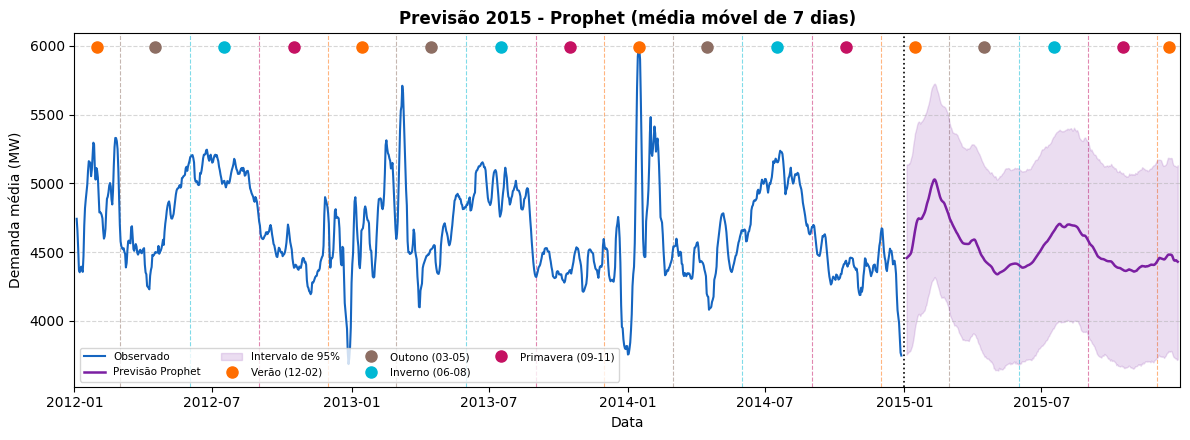

In [83]:
grafico_estacoes(y_completa, prev_final, 'Previsão 2015 - Prophet (média móvel de 7 dias)')

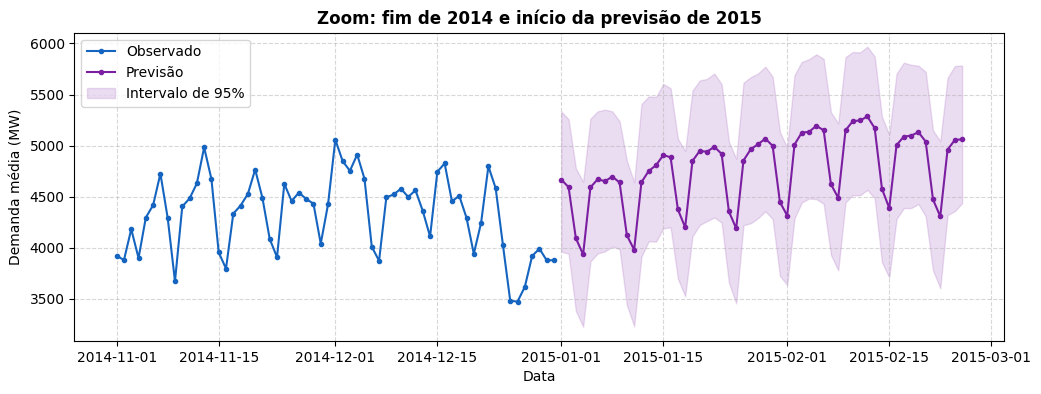

In [84]:
# Zoom nas primeiras 8 semanas de 2015
inicio = prev_final.iloc[:56]

plt.figure(figsize=(12, 4))
plt.plot(y_completa.loc['2014-11-01':], color=COR_SERIE, marker='o', markersize=3, label='Observado')
plt.plot(inicio['mean'], color=cor_escolhida, marker='o', markersize=3, label='Previsão')
plt.fill_between(inicio.index, inicio['lower'], inicio['upper'], color=cor_escolhida, alpha=0.15, label='Intervalo de 95%')
plt.title('Zoom: fim de 2014 e início da previsão de 2015', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.show()

In [85]:
# Resumo mensal da previsao de 2015 (com o real de 2014 para comparar)
resumo = prev_final[['mean', 'lower', 'upper']].groupby(prev_final.index.month).mean().round(0)
resumo['Real 2014'] = y_teste.groupby(y_teste.index.month).mean().round(0).values
resumo.index = nomes_meses
resumo.columns = ['Previsão 2015 (MW)', 'Limite inferior', 'Limite superior', 'Real 2014 (MW)']
resumo.T

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
Previsão 2015 (MW),4637.0,4918.0,4612.0,4488.0,4357.0,4437.0,4651.0,4641.0,4495.0,4384.0,4380.0,4477.0
Limite inferior,3935.0,4220.0,3917.0,3796.0,3648.0,3744.0,3946.0,3946.0,3789.0,3678.0,3682.0,3768.0
Limite superior,5329.0,5617.0,5309.0,5176.0,5058.0,5141.0,5342.0,5339.0,5189.0,5083.0,5089.0,5175.0
Real 2014 (MW),4825.0,4816.0,4398.0,4358.0,4572.0,4804.0,5090.0,4891.0,4516.0,4411.0,4324.0,4320.0


- **Perfil semanal e largura do intervalo na previsão de 2015**

In [86]:
perfil = prev_final['mean'].groupby(prev_final.index.dayofweek).mean().round(0)
perfil.index = nomes_dias
print(perfil.to_frame('Previsão média 2015 (MW)').T)

meia_largura = ((prev_final['upper'] - prev_final['lower']) / 2).iloc[28:].mean()
print("Média prevista 2015:", round(prev_final['mean'].mean()), "MW | média histórica 2012-2014:", round(y_completa.mean()), "MW")
print("Meia largura média do intervalo de 95% (depois das 4 primeiras semanas): ±", round(meia_largura), "MW")

                             Seg     Ter     Qua     Qui     Sex     Sáb  \
Previsão média 2015 (MW)  4652.0  4743.0  4744.0  4780.0  4700.0  4147.0   

                             Dom  
Previsão média 2015 (MW)  3994.0  
Média prevista 2015: 4538 MW | média histórica 2012-2014: 4665 MW
Meia largura média do intervalo de 95% (depois das 4 primeiras semanas): ± 699 MW


- **Por que o Prophet: a previsão de 2015 sem o padrão semanal (média móvel de 7 dias)**

Aqui o SARIMA (segundo colocado na validação) **não é avaliado de novo**: ele é treinado com os mesmos dados (2012 a 2014) só para mostrar o formato da previsão. A média móvel de 7 dias tira o padrão semanal, e fica só o nível previsto ao longo do ano.

Média prevista 2015 -> Prophet: 4538 MW | SARIMA: 4639 MW
Média móvel 7 dias (sem as 4 primeiras semanas):
  Prophet -> mínimo 4339 | máximo 5029 MW
  SARIMA  -> mínimo 4647 | máximo 4648 MW


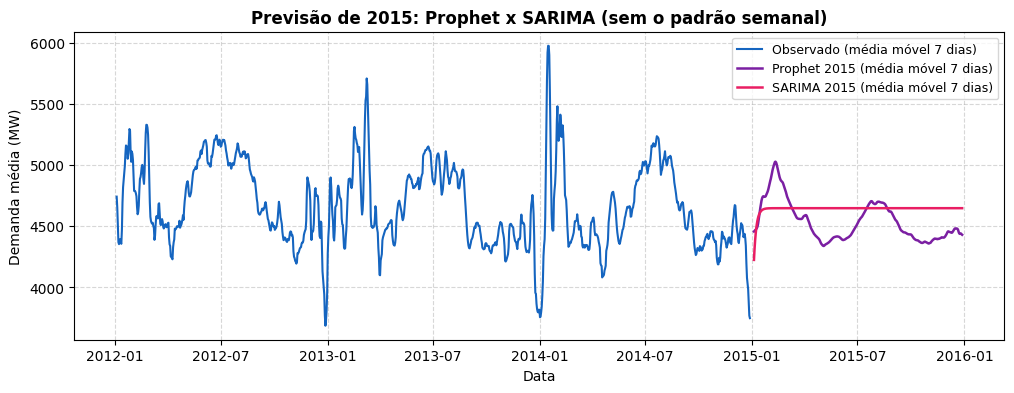

In [87]:
# SARIMA (2o colocado na validacao) treinado com 2012 a 2014, so para comparar o formato da previsao
_, prev_sarima_2015 = prever_com_intervalo(familia_segunda, config_segunda, y_completa, h)

mm_prophet = prev_final['mean'].rolling(7, center=True).mean()
mm_sarima = prev_sarima_2015['mean'].rolling(7, center=True).mean()

print("Média prevista 2015 -> Prophet:", round(prev_final['mean'].mean()), "MW | SARIMA:", round(prev_sarima_2015['mean'].mean()), "MW")
print("Média móvel 7 dias (sem as 4 primeiras semanas):")
print("  Prophet -> mínimo", round(mm_prophet.iloc[28:].min()), "| máximo", round(mm_prophet.iloc[28:].max()), "MW")
print("  SARIMA  -> mínimo", round(mm_sarima.iloc[28:].min()), "| máximo", round(mm_sarima.iloc[28:].max()), "MW")

plt.figure(figsize=(12, 4))
plt.plot(y_completa.rolling(7, center=True).mean(), color=COR_SERIE, label='Observado (média móvel 7 dias)')
plt.plot(mm_prophet, color=COR_PROPHET, linewidth=1.8, label='Prophet 2015 (média móvel 7 dias)')
plt.plot(mm_sarima, color=COR_SARIMA, linewidth=1.8, label='SARIMA 2015 (média móvel 7 dias)')
plt.title('Previsão de 2015: Prophet x SARIMA (sem o padrão semanal)', fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Demanda média (MW)')
plt.grid(linestyle='--', alpha=0.5)
plt.legend(fontsize=9)
plt.show()

- **Conclusão da previsão para 2015 (Prophet treinado com 2012 a 2014)**

  - **Média prevista de 4.538 MW** (média histórica: 4.665 MW). A tendência fica quase plana, de 4.588 para 4.538 MW.
  - **Formato ao longo do ano** (gráfico das estações):
    - pico no **verão**, em fevereiro (4.918 MW);
    - queda no **outono** até maio (4.357 MW);
    - nova subida no **inverno**, em julho e agosto (cerca de 4.650 MW);
    - **primavera** e início do verão estáveis, perto de 4.400 MW, com a queda das festas no fim do ano.
  - **Padrão semanal:** 4.650 a 4.780 MW de segunda a sexta, 4.147 MW no sábado e 3.994 MW no domingo.
  - **Intervalo de 95%:** cerca de **±700 MW** depois das primeiras semanas.

- **Por que o Prophet**

  1. **Regra do enunciado:** menor RMSE na validação (366 MW), ganhando nas festas, no resto do ano e em 2 de cada 3 dias.
  2. **A média móvel da previsão não é uma linha reta.** Quando se tira o padrão semanal (média móvel de 7 dias, último gráfico), o SARIMA vira uma **linha reta em cerca de 4.650 MW** (mínimo 4.647 e máximo 4.648 MW depois das primeiras semanas): toda a variação dele vinha só do ciclo de 7 dias. O Prophet continua mostrando um formato, entre **4.339 e 5.029 MW**: pico no verão, queda no outono, subida no inverno e o vale das festas, como nos anos observados (gráfico das estações). Assim a previsão mostra **quando** a demanda sobe, e não só um valor médio.
  3. **Datas especiais:** é o único modelo que prevê o vale das festas de fim de ano.

- **Limitações**

  - No teste de 2014 o erro (494 MW) ficou praticamente igual ao de repetir o ano anterior (487 MW). A vantagem da validação era otimista (uma única janela e uma grade grande).
  - O **pico de inverno é subestimado** (cerca de 500 a 600 MW em julho e agosto de 2014). Em 2015 isso deve se repetir: a previsão de julho e agosto (cerca de 4.650 MW) está abaixo dos invernos observados (médias de julho e agosto entre cerca de 4.800 e 5.100 MW).
  - **Ondas de calor pontuais** não são previstas: o regressor usa a temperatura suavizada do ano anterior.

- **Próximos passos**

  - **Separar frio e calor** em dois regressores. No teste, isso reduziu o erro do inverno em cerca de 30%, mas precisaria ser confirmado com mais anos de validação.
  - Com mais anos de histórico, usar a **sazonalidade anual** do próprio Prophet (`yearly_seasonality=True`), que precisa de pelo menos 2 anos no treino.
  - **Mais janelas de validação**, para a escolha depender menos de um único ano.